# FGM Risk Incidence, Mali — v2

This notebook analyses time to first FGM using prepared Mali DHS 2023–24
self-reported and daughter-reported histories. Run `00_EDA_DHS_Country_Year_v2.ipynb`
first, then run this notebook in order.

The workflow includes Kaplan–Meier curves, a survey-weighted discrete-time
logistic hazard model, age/cohort trend smoothing, and precision-weighted
BYM2 regional plus RW2 birth-cohort smoothing of direct age-band risks.
The hazard regression adjusts for ethnicity, residence, region, birth cohort,
age and reporting source. The spatial risk model smooths direct estimates;
it does not use the hazard regression coefficients or explicitly adjust for
ethnicity and residence. Self and daughter spatial estimates are fitted separately.

The boundary layer contains nine survey regions. Interviews in 2023 and 2024
belong to one 2023–24 survey, not two independent rounds. Younger cohorts
have incomplete follow-up; unsupported age-band estimates remain missing.
The model-comparison figure is descriptive, not formal validation.


## 0. Configuration, edit this block for each country run

This is the only section that should normally change between countries. Every later section reads from these settings rather than hard coding a country name or file path.

In [45]:
# Country identity
country_name   <- "Mali"
country_iso3   <- "MLI"       # ISO3 code; matches 00_EDA_DHS_Country_Year_v2.ipynb
survey_year    <- 2023
survey_folder  <- "2023-24"

project_root <- if (dir.exists("../02_Data")) ".." else "."

proc_data_dir     <- file.path(project_root, "02_Data", "processed", country_iso3)
combined_data_dir <- file.path(proc_data_dir, "combined")
output_dir        <- file.path(project_root, "03_Outputs", country_iso3)

dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)


admin_level          <- "admin1"
shapefile_path        <- file.path(project_root, "02_Data", "raw", survey_folder, "boundaries",
                                     "Mali boundaries", "shps",
                                     "sdr_subnational_boundaries.shp")
region_var_shapefile  <- "DHSREGEN"  # Mali DHS survey-region name field
standardize_region <- function(x) {
  x |> as.character() |> iconv(to = "ASCII//TRANSLIT") |> toupper() |>
    stringr::str_replace_all("[^A-Z ]", " ") |> stringr::str_squish()
}

# Age window and toggles
max_age_years <- 49   

run_spatial_model  <- file.exists(shapefile_path)   # TRUE automatically once the boundary above exists
run_change_point   <- TRUE
run_ml_crosscheck  <- TRUE

cat("Configured for:", country_name, paste0("(", country_iso3, ")"), "\n")
if (!run_spatial_model) {
  message("No admin1 boundary shapefile found at ", shapefile_path,
          ", spatial modeling (sections 11-12) will be skipped for this run.")
}

Configured for: Mali (MLI) 


## 1. Setup and packages

In [46]:
required_packages <- c(
  "tidyverse", "survey", "survival", "survminer",
  "sf", "spdep", "INLA", "SUMMER", "mgcv", "changepoint", "randomForestSRC"
)

missing_packages <- required_packages[!vapply(required_packages, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing_packages) > 0) {
  message("Missing packages, install before continuing: ", paste(missing_packages, collapse = ", "))
}

library(tidyverse)
library(survey)
library(survival)
library(survminer)
library(sf)
library(spdep)
library(mgcv)

# INLA and SUMMER are loaded lazily inside section 11 so the earlier sections
# still run on a machine where the spatial packages are not yet installed.

# A region can be left with only one sampled cluster once a domain estimate subsets the
# data (section 10), or once rounds are combined and a stratum happens to have a single
# PSU. "adjust" recenters that lonely PSU to the overall stratum mean instead of
# erroring, the standard remedy documented in ?survey::svydesign.
options(survey.lonely.psu = "adjust")

set.seed(20260101)

## 2. Load prepared data

Reads the cleaned, harmonized, multi-round file `00_EDA_DHS_Country_Year.ipynb` wrote for
this country. That notebook is what actually resolves the country's DHS variable codes
(including catching mismapped ones, e.g. this notebook previously pointed its age-at-cutting
field at the wrong DHS variable), runs the data quality checks, and derives `fgm_event`,
`time`, and `birth_cohort`. First 5 rows are printed below so you can see the incoming
data before anything else runs.

In [47]:
fgm_events_path <- file.path(combined_data_dir, paste0(country_iso3, "_fgm_events.rds"))
if (!file.exists(fgm_events_path)) {
  stop("No prepared data found at ", fgm_events_path,
       ". Run 00_EDA_DHS_Country_Year.ipynb for this country first.")
}

fgm_events <- readRDS(fgm_events_path) |>
  dplyr::filter(
    is.finite(time), time >= 0, time <= max_age_years,
    record_type != "self" | dplyr::between(age, 15, 49)
  ) |>
  dplyr::mutate(
    # Match the region-name convention expected by the existing spatial code.
    region = standardize_region(region),
    # Match the cohort-label convention used throughout the existing pipeline.
    birth_cohort = stringr::str_replace(
      birth_cohort, "^(\\d{4})-(\\d{4})$", "\\1 to \\2"
    ),
    birth_cohort = factor(birth_cohort, levels = sort(unique(birth_cohort)))
  )

# Audit logically impossible daughter histories before excluding them.
invalid_daughter_events <- fgm_events |>
  dplyr::filter(
    record_type == "daughter", fgm_event == 1,
    !is.na(time), !is.na(age), time > age
  )
cat("Daughter histories excluded because FGM age exceeds current age:",
    nrow(invalid_daughter_events), "\n")

fgm_events <- fgm_events |>
  dplyr::filter(!(record_type == "daughter" & fgm_event == 1 & time > age))

cat("Rows loaded:", nrow(fgm_events), "FGM histories from Mali DHS 2023-24; interview years:",
    paste(sort(unique(fgm_events$survey_year)), collapse = ", "), "\n\n")

head(fgm_events, 5)

Daughter histories excluded because FGM age exceeds current age: 1 
Rows loaded: 34507 FGM histories from Mali DHS 2023-24; interview years: 2023, 2024 



id,record_type,survey_type,survey_year,country,region,cluster,urban_rural,weight,psu,strata,lat,lon,missing_gps,age,birth_year,birth_cohort,ethnicity,fgm_event,time
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<fct>,<chr>,<int>,<dbl>
2023-1-1-2,self,DHS,2023,MLI,KAYES,1,urban,0.762535,1,2,NA,NA,NA,28,1995,1995 to 1999,bambara,1,0
2023-1-5-2,self,DHS,2023,MLI,KAYES,1,urban,0.762535,1,2,NA,NA,NA,28,1995,1995 to 1999,sarakole/soninke/marka,1,0
2023-1-5-6,self,DHS,2023,MLI,KAYES,1,urban,0.762535,1,2,NA,NA,NA,21,2002,2000 to 2004,sarakole/soninke/marka,1,0
2023-1-5-8,self,DHS,2023,MLI,KAYES,1,urban,0.762535,1,2,NA,NA,NA,16,2007,2005 to 2009,bambara,1,0
2023-1-5-9,self,DHS,2023,MLI,KAYES,1,urban,0.762535,1,2,NA,NA,NA,17,2006,2005 to 2009,bambara,1,0


## 3. Data quality

The preparation notebook derives FGM status and event/censoring time. The loading
cell above removes missing or out-of-range times, restricts self-reported histories
to ages 15–49, and excludes daughters whose age at FGM exceeds current age.
The same filtered data are used throughout; do not reload the unfiltered file
between model and plotting sections.


In [48]:
dplyr::count(fgm_events, survey_year, fgm_event)
dplyr::glimpse(fgm_events)

survey_year,fgm_event,n
<dbl>,<int>,<int>
2023,0,2210
2023,1,7191
2024,0,8013
2024,1,17093


Rows: 34,507
Columns: 20
$ id           <chr> "2023-1-1-2", "2023-1-5-2", "2023-1-5-6", "2023-1-5-8", "~
$ record_type  <chr> "self", "self", "self", "self", "self", "self", "self", "~
$ survey_type  <chr> "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "DHS", "~
$ survey_year  <dbl> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 202~
$ country      <chr> "MLI", "MLI", "MLI", "MLI", "MLI", "MLI", "MLI", "MLI", "~
$ region       <chr> "KAYES", "KAYES", "KAYES", "KAYES", "KAYES", "KAYES", "KA~
$ cluster      <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ~
$ urban_rural  <chr> "urban", "urban", "urban", "urban", "urban", "urban", "ur~
$ weight       <dbl> 0.762535, 0.762535, 0.762535, 0.762535, 0.762535, 0.76253~
$ psu          <dbl> 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ~
$ strata       <dbl> 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ~
$ lat          <dbl> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, N~
$ lon          

## 4. The FGM event

Each respondent is already a time to event record: `fgm_event` is 1 if she was cut and
`time` is her age at cutting, or `fgm_event` is 0 and `time` is her age at interview,
censored at `max_age_years`, if she had not been cut by the time of the survey. Birth
cohort was reconstructed from `birth_year` (the survey's own respondent year of birth
variable), giving decades of retrospective cohort coverage from a single cross sectional
survey, the same device the original UNFPA analysis relies on.

In [49]:
dplyr::count(fgm_events, fgm_event)

fgm_event,n
<int>,<int>
0,10223
1,24284


## 5. Create person time data

Expand each respondent into one row per completed year of life up to her event or censoring age, the format a discrete time hazard model in section 8 requires. This mirrors the person month construction used by the SUMMER package for under five mortality, applied here to age at cutting instead of age at death.

In [50]:
make_person_time <- function(df) {
  df |>
    dplyr::mutate(row_id = dplyr::row_number()) |>
    dplyr::rowwise() |>
    dplyr::reframe(
      row_id, id, survey_type, survey_year, country, region, cluster, urban_rural, weight,
      birth_cohort, ethnicity, record_type,
      age_year = 0:floor(time),
      event = dplyr::if_else(age_year == floor(time) & fgm_event == 1, 1L, 0L)
    ) |>
    dplyr::ungroup()
}

person_time <- make_person_time(fgm_events)
readr::write_csv(person_time, file.path(proc_data_dir, paste0(country_iso3, "_person_time.csv")))
cat("Person time rows:", nrow(person_time), "from", dplyr::n_distinct(person_time$id), "respondents\n")

Person time rows: 216378 from 34507 respondents


## 6. Kaplan Meier baseline

Reproduce the original UNFPA approach first, before moving to the formal hazard model, so the two can be compared directly in section 15.

In [51]:
# km_fit <- survival::survfit(
#   survival::Surv(time, fgm_event) ~ birth_cohort,
#   data = fgm_events
# )

# survminer::ggsurvplot(
#   km_fit,
#   data = fgm_events,
#   xlab = "Age of girl or woman",
#   ylab = "Probability of not experiencing FGM",
#   legend.title = "Birth cohort",
#   ggtheme = ggplot2::theme_minimal()
# )

In [52]:
fgm_events_self_plot     <- fgm_events |> dplyr::filter(record_type == "self")     |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))
fgm_events_daughter_plot <- fgm_events |> dplyr::filter(record_type == "daughter") |> dplyr::mutate(birth_cohort = droplevels(birth_cohort))


Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message in ggplot2::margin(top = 16):
"`...` must be empty.
x Problematic argument:
* top = 16"
Warning message in ggplot2::margin(right = 18):
"`...` must be empty.
x Problematic argument:
* right = 18"
Warning message in ggplot2::margin(top = 12):
"`...` must be empty.
x Problematic argument:
* top = 12"
Warning message in ggplot2::margin(top = 10, bottom = 8):
"`...` must be empty.
x Problematic arguments:
* top = 10
* bottom = 8"
Warning message in ggplot2::margin(bottom = 20):
"`...` must be empty.
x Problematic argument:
* bottom = 20"
Warning message in ggplot2::margin(top = 25, right = 30, bottom = 25, left = 25):
"`...` must be empty.
x Problematic arguments:
* top = 25
* right = 30
* bottom = 25
* left = 25"


Kaplan<U+2013>Meier plot saved to: ../03_Outputs/MLI/FGM_Kaplan_Meier_self.png 
Kaplan<U+2013>Meier PDF saved to: ../03_Outputs/MLI/FGM_Kaplan_Meier_self.pdf 


Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message in ggplot2::margin(top = 16):
"`...` must be empty.
x Problematic argument:
* top = 16"
Warning message in ggplot2::margin(right = 18):
"`...` must be empty.
x Problematic argument:
* right = 18"
Warning message in ggplot2::margin(top = 12):
"`...` must be empty.
x Problematic argument:
* top = 12"
Warning message in ggplot2::margin(top = 10, bottom = 8):
"`...` must be empty.
x Problematic arguments:
* top = 10
* bottom = 8"
Warning message in ggplot2::margin(bottom = 20):
"`...` must be empty.
x Problematic argument:
* bottom = 20"
Warning message in ggplot2::margin(top = 25, right = 30, bottom = 25, left = 25):
"`...` must be empty.
x Problematic arguments:
* top = 25
* right = 30
* bottom = 25
* left = 25"


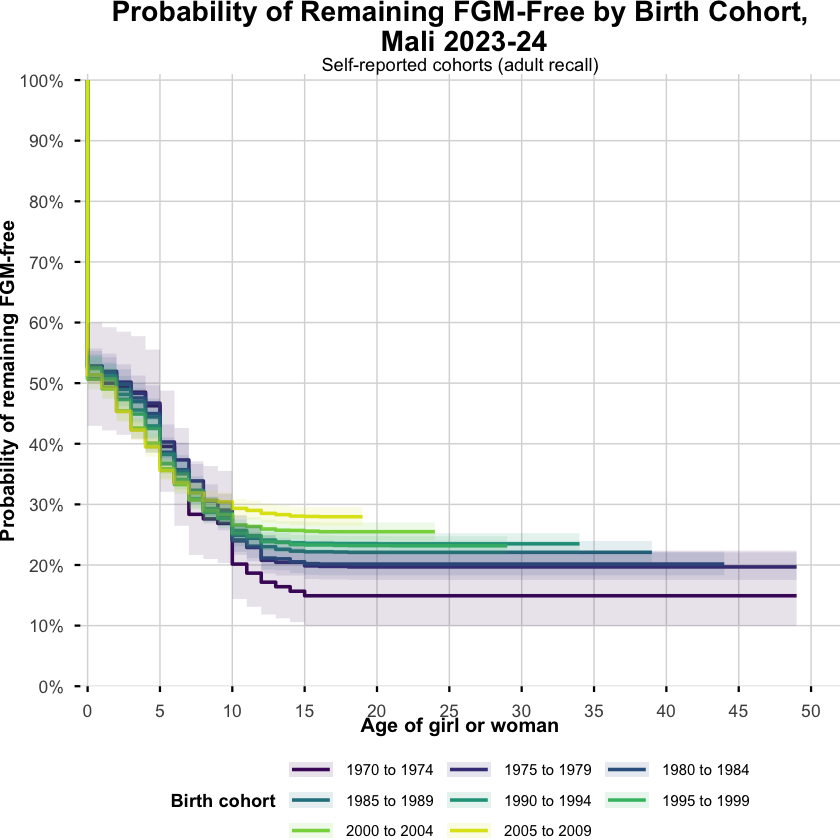

Kaplan<U+2013>Meier plot saved to: ../03_Outputs/MLI/FGM_Kaplan_Meier_daughter.png 
Kaplan<U+2013>Meier PDF saved to: ../03_Outputs/MLI/FGM_Kaplan_Meier_daughter.pdf 


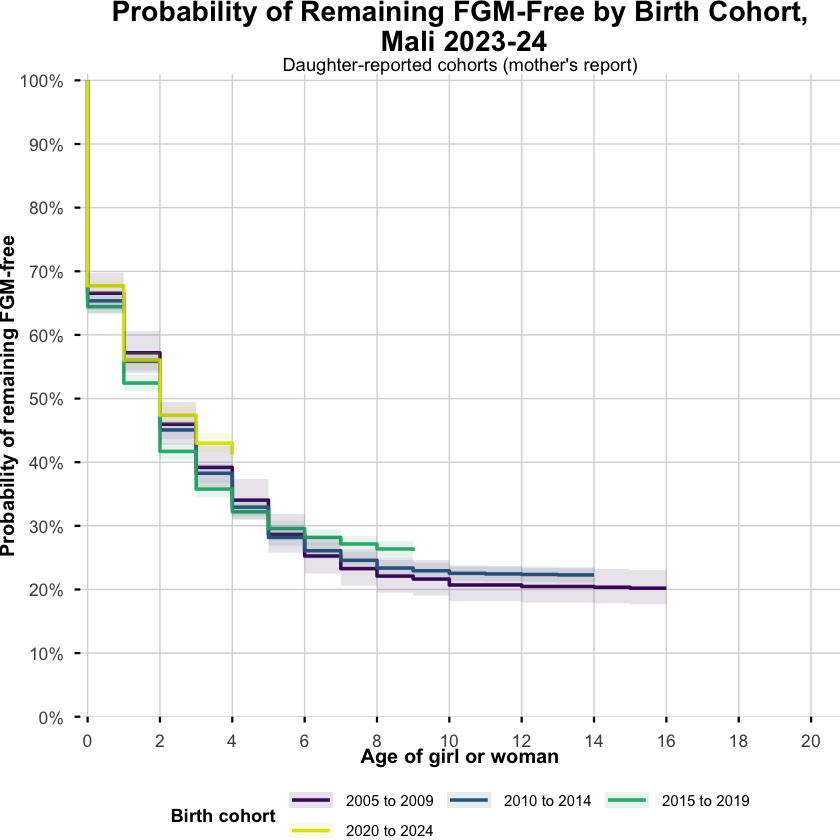

In [53]:

# ============================================================
# Kaplan–Meier curves: probability of remaining FGM-free
# Refined for Mali's full 0%–100% survival range
# ============================================================

# Use the same ordered cohort levels in both reporting groups.
# Converting explicitly to factor avoids the earlier droplevels()
# error when birth_cohort is stored as character.
cohort_levels <- fgm_events |>
  dplyr::pull(birth_cohort) |>
  as.character() |>
  unique() |>
  sort()

fgm_events_self_plot <- fgm_events |>
  dplyr::filter(
    record_type == "self",
    !is.na(time),
    !is.na(fgm_event),
    !is.na(birth_cohort)
  ) |>
  dplyr::mutate(
    birth_cohort = droplevels(
      factor(birth_cohort, levels = cohort_levels)
    )
  )

fgm_events_daughter_plot <- fgm_events |>
  dplyr::filter(
    record_type == "daughter",
    !is.na(time),
    !is.na(fgm_event),
    !is.na(birth_cohort)
  ) |>
  dplyr::mutate(
    birth_cohort = droplevels(
      factor(birth_cohort, levels = cohort_levels)
    )
  )


build_km_plot <- function(
    plot_data,
    subtitle_label,
    xlim_max,
    break_by,
    file_suffix
) {

  # ----------------------------------------------------------
  # Validate the input
  # ----------------------------------------------------------

  if (nrow(plot_data) == 0L) {
    stop("No observations are available for the ", file_suffix, " Kaplan–Meier plot.")
  }

  if (nlevels(plot_data$birth_cohort) == 0L) {
    stop("No valid birth cohorts are available for the ", file_suffix, " plot.")
  }

  if (!all(plot_data$fgm_event %in% c(0, 1))) {
    stop("fgm_event must contain only 0, 1, or NA.")
  }

  # ----------------------------------------------------------
  # Fit the Kaplan–Meier model
  # ----------------------------------------------------------

  km_fit <- survival::survfit(
    survival::Surv(time, fgm_event) ~ birth_cohort,
    data = plot_data
  )

  n_cohorts <- nlevels(plot_data$birth_cohort)

  cohort_palette <- viridisLite::viridis(
    n = n_cohorts,
    option = "D",
    begin = 0.05,
    end = 0.95,
    direction = 1
  )

  # ----------------------------------------------------------
  # Build the base Kaplan–Meier plot
  #
  # Mali's FGM-free survival estimates fall well below 70%.
  # The complete 0–100% range is therefore required.
  # ----------------------------------------------------------

  km_plot <- survminer::ggsurvplot(
    fit = km_fit,
    data = plot_data,
    conf.int = TRUE,
    conf.int.alpha = 0.12,
    censor = FALSE,
    xlab = "Age of girl or woman",
    ylab = "Probability of remaining FGM-free",
    xlim = c(0, xlim_max),
    ylim = c(0, 1),
    break.time.by = break_by,
    legend.title = "Birth cohort",
    legend = "bottom",
    legend.labs = levels(plot_data$birth_cohort),
    palette = cohort_palette,
    ggtheme = ggplot2::theme_minimal(base_size = 14)
  )

  # ----------------------------------------------------------
  # Identify where follow-up ends for each cohort
  # ----------------------------------------------------------

  cohort_followup <- plot_data |>
    dplyr::group_by(birth_cohort) |>
    dplyr::summarise(
      max_age = max(time, na.rm = TRUE),
      .groups = "drop"
    ) |>
    dplyr::filter(
      is.finite(max_age),
      max_age < xlim_max
    ) |>
    dplyr::mutate(
      birth_cohort = as.character(birth_cohort)
    )

  final_survival <- broom::tidy(km_fit) |>
    dplyr::mutate(
      birth_cohort = stringr::str_remove(
        strata,
        "^birth_cohort="
      )
    ) |>
    dplyr::group_by(birth_cohort) |>
    dplyr::slice_max(
      order_by = time,
      n = 1,
      with_ties = FALSE
    ) |>
    dplyr::ungroup() |>
    dplyr::select(
      birth_cohort,
      estimate
    )

  end_points <- cohort_followup |>
    dplyr::left_join(
      final_survival,
      by = "birth_cohort"
    ) |>
    dplyr::filter(!is.na(estimate))

  # ----------------------------------------------------------
  # Refine the plot
  # ----------------------------------------------------------

  km_plot$plot <- km_plot$plot +

    # Mark the end of observed follow-up for incomplete cohorts.
    # ggplot2::geom_point(
    #   data = end_points,
    #   mapping = ggplot2::aes(
    #     x = max_age,
    #     y = estimate,
    #     color = birth_cohort
    #   ),
    #   shape = 1,
    #   size = 3,
    #   stroke = 1.2,
    #   show.legend = FALSE,
    #   inherit.aes = FALSE
    # ) +

    # ggrepel::geom_text_repel(
    #   data = end_points,
    #   mapping = ggplot2::aes(
    #     x = max_age,
    #     y = estimate,
    #     label = paste0(observed = "to age ", max_age)
    #   ),
    #   size = 3,
    #   color = "grey25",
    #   min.segment.length = 0,
    #   seed = 1,
    #   show.legend = FALSE,
    #   inherit.aes = FALSE
    # ) +

    ggplot2::labs(
      title = "Probability of Remaining FGM-Free by Birth Cohort,\n Mali 2023-24",
      subtitle = paste0(
        subtitle_label,
        ""
      ),
      x = "Age of girl or woman",
      y = "Probability of remaining FGM-free"
    ) +

    ggplot2::scale_x_continuous(
      breaks = seq(0, xlim_max, by = break_by),
      limits = c(0, xlim_max),
      expand = ggplot2::expansion(mult = c(0.01, 0.04))
    ) +

    # Full scale required for Mali.
    ggplot2::scale_y_continuous(
      breaks = seq(0, 1, by = 0.10),
      limits = c(0, 1),
      labels = scales::percent_format(accuracy = 1),
      expand = ggplot2::expansion(mult = c(0, 0.01))
    ) +

    ggplot2::theme(
      plot.title = ggplot2::element_text(
        face = "bold",
        size = 17,
        hjust = 0.5,
        margin = ggplot2::margin(top = 10, bottom = 8)
      ),

      plot.subtitle = ggplot2::element_text(
        size = 11,
        hjust = 0.5,
        lineheight = 1.15,
        margin = ggplot2::margin(bottom = 20)
      ),

      axis.title.x = ggplot2::element_text(
        face = "bold",
        size = 12,
        margin = ggplot2::margin(top = 16)
      ),

      axis.title.y = ggplot2::element_text(
        face = "bold",
        size = 12,
        margin = ggplot2::margin(right = 18)
      ),

      axis.text.x = ggplot2::element_text(
        size = 10.5,
        angle = 0,
        hjust = 0.5,
        vjust = 0.5
      ),

      axis.text.y = ggplot2::element_text(size = 10.5),

      legend.position = "bottom",
      legend.direction = "horizontal",
      legend.box = "vertical",
      legend.justification = "center",

      legend.title = ggplot2::element_text(
        face = "bold",
        size = 11
      ),

      legend.text = ggplot2::element_text(size = 9),

      legend.key.width = grid::unit(1.0, "cm"),
      legend.key.height = grid::unit(0.4, "cm"),
      legend.spacing.x = grid::unit(0.10, "cm"),
      legend.margin = ggplot2::margin(top = 12),

      panel.grid.major.x = ggplot2::element_line(
        colour = "grey85",
        linewidth = 0.4
      ),

      panel.grid.major.y = ggplot2::element_line(
        colour = "grey85",
        linewidth = 0.4
      ),

      panel.grid.minor = ggplot2::element_blank(),

      plot.margin = ggplot2::margin(
        top = 25,
        right = 30,
        bottom = 25,
        left = 25
      )
    ) +

    ggplot2::guides(
      colour = ggplot2::guide_legend(
        ncol = 3,
        byrow = TRUE
      ),
      fill = ggplot2::guide_legend(
        ncol = 3,
        byrow = TRUE
      )
    )

  # ----------------------------------------------------------
  # Display and save
  # ----------------------------------------------------------

  print(km_plot)

  dir.create(
    output_dir,
    recursive = TRUE,
    showWarnings = FALSE
  )

  png_path <- file.path(
    output_dir,
    paste0("FGM_Kaplan_Meier_", file_suffix, ".png")
  )

  pdf_path <- file.path(
    output_dir,
    paste0("FGM_Kaplan_Meier_", file_suffix, ".pdf")
  )

  ggplot2::ggsave(
    filename = png_path,
    plot = km_plot$plot,
    width = 17,
    height = 14,
    units = "in",
    dpi = 300,
    bg = "white"
  )

  ggplot2::ggsave(
    filename = pdf_path,
    plot = km_plot$plot,
    width = 17,
    height = 14,
    units = "in",
    device = grDevices::cairo_pdf,
    bg = "white"
  )

  cat("Kaplan–Meier plot saved to:", png_path, "\n")
  cat("Kaplan–Meier PDF saved to:", pdf_path, "\n")

  return(km_fit)
}


# ============================================================
# Self-reported cohorts
# ============================================================

km_fit_self <- build_km_plot(
  plot_data = fgm_events_self_plot,
  subtitle_label = "Self-reported cohorts (adult recall)",
  xlim_max = 50,
  break_by = 5,
  file_suffix = "self"
)


# ============================================================
# Daughter-reported cohorts
# ============================================================

km_fit_daughter <- build_km_plot(
  plot_data = fgm_events_daughter_plot,
  subtitle_label = "Daughter-reported cohorts (mother's report)",
  xlim_max = 20,
  break_by = 2,
  file_suffix = "daughter"
)

## 7. Estimate FGM incidence risk

Convert the Kaplan Meier survival probability into a cumulative risk table at a set of reference ages

In [54]:
# reference_ages <- c(1, 2, 5, 8, 10, 15, 18)
# #reference_ages <- seq(1, 50, by = 1)

# risk_table <- summary(km_fit, times = reference_ages, extend = TRUE)

# risk_by_age <- tibble::tibble(
#   birth_cohort = risk_table$strata,
#   age          = risk_table$time,
#   survival     = risk_table$surv,
#   fgm_risk     = 1 - risk_table$surv,
#   lower_ci     = 1 - risk_table$upper,
#   upper_ci     = 1 - risk_table$lower
# )

# readr::write_csv(risk_by_age, file.path(output_dir, paste0(country_iso3, "_km_risk_by_age.csv")))
# #risk_by_age

In [55]:
reference_ages <- c(1, 2, 5, 8, 10, 15, 18)

build_risk_table <- function(km_fit, record_type_label) {
  risk_table <- summary(km_fit, times = reference_ages, extend = TRUE)
  tibble::tibble(
    #birth_cohort = risk_table$strata,
    birth_cohort = stringr::str_remove(as.character(risk_table$strata), "^birth_cohort="),
    age          = risk_table$time,
    survival     = risk_table$surv,
    fgm_risk     = 1 - risk_table$surv,
    lower_ci     = 1 - risk_table$upper,
    upper_ci     = 1 - risk_table$lower,
    record_type  = record_type_label
  )
}

risk_by_age <- dplyr::bind_rows(
  build_risk_table(km_fit_self, "self"),
  build_risk_table(km_fit_daughter, "daughter")
)

readr::write_csv(risk_by_age, file.path(output_dir, paste0(country_iso3, "_km_risk_by_age.csv")))
#print(risk_by_age, n = Inf, width = Inf)


In [56]:
display_risk_table <- function(data, record_label) {
  cat("\n=====", record_label, "reported: FGM risk by age and birth cohort =====\n")
  table_to_show <- data |>
    dplyr::arrange(birth_cohort, age) |>
    dplyr::mutate(
      fgm_risk = scales::percent(fgm_risk, accuracy = 0.1),
      lower_ci = scales::percent(lower_ci, accuracy = 0.1),
      upper_ci = scales::percent(upper_ci, accuracy = 0.1)
    ) |>
    dplyr::select(birth_cohort, age, fgm_risk, lower_ci, upper_ci)
  IRdisplay::display(as.data.frame(table_to_show))
}

display_risk_table(risk_by_age |> dplyr::filter(record_type == "self"), "Self")
display_risk_table(risk_by_age |> dplyr::filter(record_type == "daughter"), "Daughter")


birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
1970 to 1974,1,50.0%,40.8%,57.8%
1970 to 1974,2,50.7%,41.5%,58.5%
1970 to 1974,5,60.4%,51.2%,67.9%
1970 to 1974,8,72.4%,63.7%,79.0%
1970 to 1974,10,79.9%,71.8%,85.6%
1970 to 1974,15,85.1%,77.6%,90.0%
1970 to 1974,18,85.1%,77.6%,90.0%
1975 to 1979,1,48.1%,45.1%,50.8%
1975 to 1979,2,49.8%,46.9%,52.6%



===== Self reported: FGM risk by age and birth cohort =====


birth_cohort,age,fgm_risk,lower_ci,upper_ci
<chr>,<dbl>,<chr>,<chr>,<chr>
2005 to 2009,1,42.8%,39.4%,46.0%
2005 to 2009,2,54.0%,50.6%,57.3%
2005 to 2009,5,71.3%,68.1%,74.2%
2005 to 2009,8,77.9%,74.9%,80.5%
2005 to 2009,10,79.3%,76.4%,81.8%
2005 to 2009,15,79.8%,76.9%,82.3%
2005 to 2009,18,79.8%,76.9%,82.3%
2010 to 2014,1,44.1%,42.7%,45.6%
2010 to 2014,2,54.9%,53.4%,56.4%



===== Daughter reported: FGM risk by age and birth cohort =====


Interpret the Mali Kaplan–Meier estimates from the tables and figures generated above. Compare cohorts only at ages where they have adequate observed follow-up. Daughter estimates for the youngest cohorts are provisional because those cohorts have not completed childhood or adolescence; estimates beyond their observed ages must not be interpreted as completed cumulative risk.

## 8. Discrete-time hazard model

The primary model is a survey-weighted logistic regression on annual person-time
records, with covariates fitted jointly. Exponentiated coefficients are conditional
annual odds ratios, not sampling weights. The separate exploratory Cox frailty
model is not survey-weighted; check convergence before interpreting its results.


In [57]:
hazard_data <- person_time |>
  dplyr::left_join(
    fgm_events |> dplyr::select(id, survey_type, birth_cohort),
    by = c("id", "survey_type", "birth_cohort")
  )

# Design based discrete time hazard model, no frailty, as a first pass.
hazard_design <- survey::svydesign(
  ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight,
  data = hazard_data, nest = TRUE
)

survey_type_term <- if (dplyr::n_distinct(hazard_data$survey_type) > 1) " + survey_type" else ""
record_type_term  <- if (dplyr::n_distinct(hazard_data$record_type) > 1) " + record_type" else ""

hazard_model_design_based <- survey::svyglm(
  as.formula(paste0("event ~ age_year + birth_cohort + urban_rural + region + ethnicity",
                     survey_type_term, record_type_term)),
  design = hazard_design, family = quasibinomial()
)

summary(hazard_model_design_based)

# Frailty extension, an unobserved cluster level random effect capturing
# unmeasured shared cultural or social exposure, recommended in section 2.1
# on the strength of the Ethiopian frailty comparison study.
hazard_model_frailty <- survival::coxph(
  as.formula(paste0(
    "survival::Surv(age_year, age_year + 1, event) ~ birth_cohort + urban_rural + region + ethnicity",
    survey_type_term, record_type_term, " + survival::frailty(cluster)"
  )),
  data = hazard_data
)

summary(hazard_model_frailty)


Call:
svyglm(formula = as.formula(paste0("event ~ age_year + birth_cohort + urban_rural + region + ethnicity", 
    survey_type_term, record_type_term)), design = hazard_design, 
    family = quasibinomial())

Survey design:
survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, 
    region), weights = ~weight, data = hazard_data, nest = TRUE)

Coefficients:
                                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)                      -1.007469   0.157852  -6.382 5.11e-10 ***
age_year                         -0.198234   0.009774 -20.282  < 2e-16 ***
birth_cohort1975 to 1979          0.014734   0.127646   0.115 0.908169    
birth_cohort1980 to 1984          0.055559   0.122363   0.454 0.650055    
birth_cohort1985 to 1989          0.057120   0.124627   0.458 0.646984    
birth_cohort1990 to 1994          0.173287   0.120512   1.438 0.151282    
birth_cohort1995 to 1999          0.193528   0.117668   1.645 0.100863    
birth_cohort2000 to 2004

Warning message in coxpenal.fit(X, Y, istrat, offset, init = init, control, weights = weights, :
"Inner loop failed to coverge for iterations 2 3 4"
Warning message in sqrt((diag(object$var2))[kk]):
"NaNs produced"
Warning message in sqrt((diag(object$var2))[kk]):
"NaNs produced"


Call:
survival::coxph(formula = as.formula(paste0("survival::Surv(age_year, age_year + 1, event) ~ birth_cohort + urban_rural + region + ethnicity", 
    survey_type_term, record_type_term, " + survival::frailty(cluster)")), 
    data = hazard_data)

  n= 216378, number of events= 24284 

                          coef     se(coef) se2     Chisq   DF    p       
birth_cohort1975 to 1979  -0.04579 0.10014  0.10012    0.21   1.0  6.5e-01
birth_cohort1980 to 1984  -0.02237 0.09877  0.09875    0.05   1.0  8.2e-01
birth_cohort1985 to 1989   0.02456 0.09806  0.09804    0.06   1.0  8.0e-01
birth_cohort1990 to 1994   0.07963 0.09766  0.09764    0.66   1.0  4.1e-01
birth_cohort1995 to 1999   0.09315 0.09705  0.09703    0.92   1.0  3.4e-01
birth_cohort2000 to 2004   0.11516 0.09689  0.09688    1.41   1.0  2.3e-01
birth_cohort2005 to 2009   0.08994 0.09700  0.09699    0.86   1.0  3.5e-01
birth_cohort2010 to 2014   0.12368 0.10590  0.10588    1.36   1.0  2.4e-01
birth_cohort2015 to 2019   0.12307 

## 9. Cohort and trend smoothing

Replace a low flexibility parametric cohort effect with a Bayesian penalized spline, the same smoothing device UN IGME uses in its Bayesian B spline bias reduction model for under five mortality, to avoid both overfitting single year cohorts and underfitting a genuinely nonlinear decline.

In [58]:
# cohort_numeric <- hazard_data |>
#   dplyr::mutate(cohort_mid = as.numeric(stringr::str_extract(birth_cohort, "^[0-9]+")) + 2)

# trend_model <- mgcv::gam(
#   event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", k = 10) +
#     urban_rural + region,
#   family = binomial(),
#   weights = weight,
#   data = cohort_numeric
# )

# summary(trend_model)
# plot(trend_model, pages = 1, shade = TRUE)

Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$initialize):
"non-integer #successes in a binomial glm!"
Warning message in eval(family$i


Family: binomial 
Link function: logit 

Formula:
event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", 
    k = 10) + urban_rural + region + record_type

Parametric coefficients:
                 Estimate Std. Error z value Pr(>|z|)    
(Intercept)      -7.09758    2.27872  -3.115 0.001841 ** 
urban_ruralurban  0.07408    0.02482   2.985 0.002839 ** 
regionGAO        -6.67611    0.62683 -10.651  < 2e-16 ***
regionKAYES       0.97295    0.03645  26.691  < 2e-16 ***
regionKIDAL      -2.85907    0.86494  -3.306 0.000948 ***
regionKOULIKORO   0.18888    0.03331   5.670 1.43e-08 ***
regionMOPTI      -0.56047    0.03734 -15.009  < 2e-16 ***
regionSEGOU      -0.09614    0.03434  -2.800 0.005111 ** 
regionSIKASSO    -0.19738    0.03224  -6.121 9.28e-10 ***
regionTOMBOUCTOU -3.28289    0.14990 -21.900  < 2e-16 ***
record_typeself   0.14429    0.04362   3.308 0.000941 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Approximate significance of smooth terms:
 

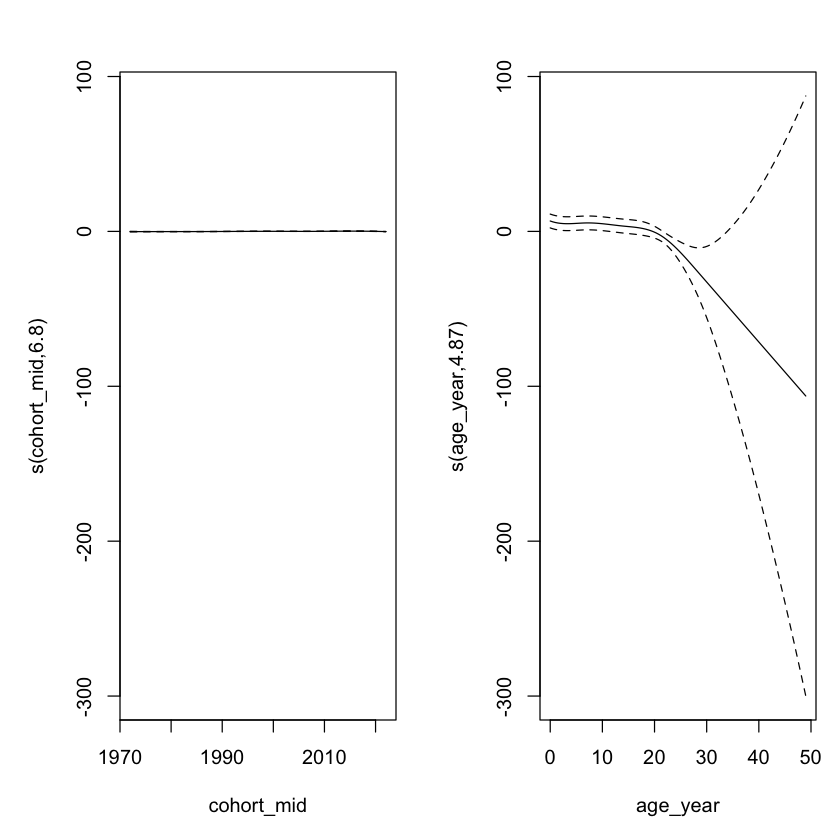

In [59]:
cohort_numeric <- hazard_data |>
  dplyr::mutate(
    cohort_mid  = as.numeric(stringr::str_extract(birth_cohort, "^[0-9]+")) + 2,
    record_type = factor(record_type)
  )

trend_model <- mgcv::gam(
  event ~ s(cohort_mid, bs = "ps", k = 10) + s(age_year, bs = "ps", k = 10) +
    urban_rural + region + record_type,
  family = binomial(),
  weights = weight,
  data = cohort_numeric
)

summary(trend_model)
plot(trend_model, pages = 1, shade = TRUE)


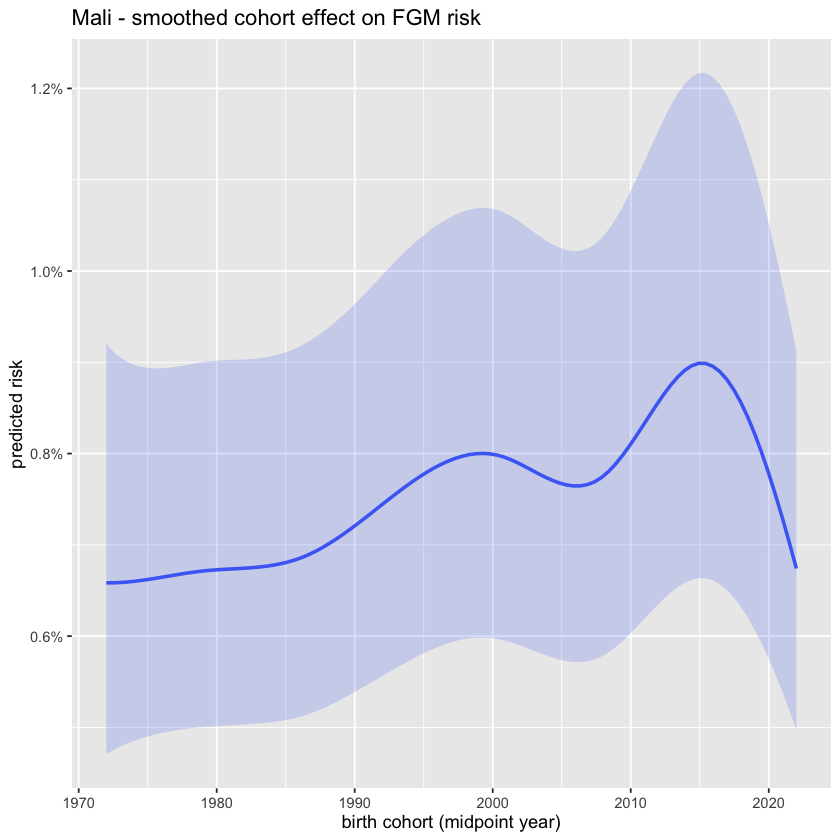

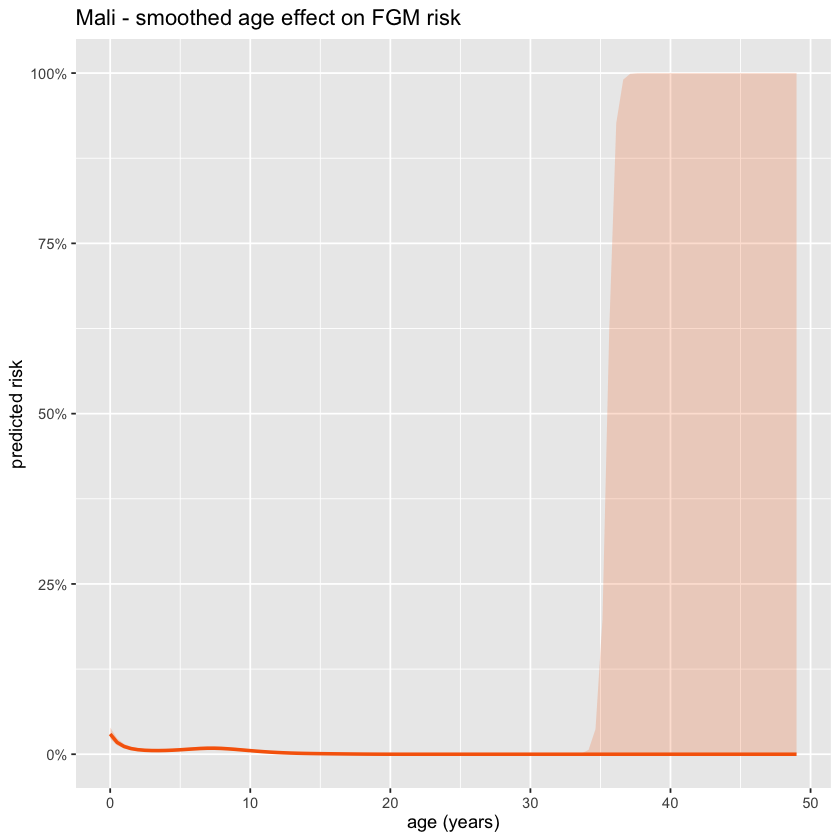

In [60]:
suppressMessages(library(scales))

# Reference levels for the covariates NOT being plotted — since the model is additive,
# holding these fixed only shifts the curve's baseline, not its shape, so any fixed
# choice works for showing how cohort/age themselves affect risk.
ref_urban_rural <- names(sort(table(cohort_numeric$urban_rural), decreasing = TRUE))[1]
ref_region      <- names(sort(table(cohort_numeric$region), decreasing = TRUE))[1]
ref_record_type <- factor("self", levels = levels(cohort_numeric$record_type))

predict_smooth <- function(var_name, grid_values, other_fixed_at) {
  newdata <- tibble(!!var_name := grid_values) |> bind_cols(other_fixed_at)
  pred <- predict(trend_model, newdata = newdata, type = "link", se.fit = TRUE)
  newdata |>
    mutate(
      fit   = plogis(pred$fit),
      lower = plogis(pred$fit - 1.96 * pred$se.fit),
      upper = plogis(pred$fit + 1.96 * pred$se.fit)
    )
}

cohort_pred <- predict_smooth(
  "cohort_mid",
  seq(min(cohort_numeric$cohort_mid), max(cohort_numeric$cohort_mid), length.out = 100),
  tibble(age_year = median(cohort_numeric$age_year), urban_rural = ref_urban_rural,
         region = ref_region, record_type = ref_record_type)
)

age_pred <- predict_smooth(
  "age_year",
  seq(min(cohort_numeric$age_year), max(cohort_numeric$age_year), length.out = 100),
  tibble(cohort_mid = median(cohort_numeric$cohort_mid), urban_rural = ref_urban_rural,
         region = ref_region, record_type = ref_record_type)
)



p_cohort <- ggplot(cohort_pred, aes(x = cohort_mid, y = fit)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = "#4C6EF5", alpha = 0.2) +
  geom_line(color = "#4C6EF5", linewidth = 1) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- smoothed cohort effect on FGM risk"),
       x = "birth cohort (midpoint year)", y = "predicted risk")

p_age <- ggplot(age_pred, aes(x = age_year, y = fit)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), fill = "#F76707", alpha = 0.2) +
  geom_line(color = "#F76707", linewidth = 1) +
  scale_y_continuous(labels = scales::percent) +
  labs(title = paste(country_name, "- smoothed age effect on FGM risk"),
       x = "age (years)", y = "predicted risk")

print(p_cohort)
print(p_age)


## 10. Subnational small area estimation setup

Prepare the design based direct estimates by region and cohort or period, and load the administrative boundaries and spatial adjacency structure the smoothing step in section 11 needs, following the SUMMER package architecture described in section 2.2 of the improved methodology document.

# Direct estimates per source

#old code

In [61]:
# direct_self <- survey::svyby(
#   ~event, ~region + birth_cohort,
#   subset(hazard_design, record_type == "self"), survey::svymean, na.rm = TRUE
# ) |> dplyr::mutate(record_type = "self")

# direct_daughter <- survey::svyby(
#   ~event, ~region + birth_cohort,
#   subset(hazard_design, record_type == "daughter"), survey::svymean, na.rm = TRUE
# ) |> dplyr::mutate(record_type = "daughter")

# readr::write_csv(direct_self,     file.path(output_dir, paste0(country_iso3, "_direct_estimates_self.csv")))
# readr::write_csv(direct_daughter, file.path(output_dir, paste0(country_iso3, "_direct_estimates_daughter.csv")))

# if (run_spatial_model) {
#   boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
#   adjacency  <- spdep::poly2nb(boundaries, row.names = boundaries[[region_var_shapefile]])
#   adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)
#   cat("Loaded", nrow(boundaries), "regions and built the adjacency matrix\n")
# } else {
#   cat("Spatial model disabled for this run, skip boundary and adjacency loading\n")
# }


#final-age band specific cumulative risk

In [62]:
surv_at_t <- function(km_fit, t) {
  if (t <= 0) return(list(surv = 1, varlog = 0))
  before <- which(km_fit$time <= t)
  if (length(before) == 0) return(list(surv = 1, varlog = 0))
  idx <- max(before)
  list(surv = km_fit$surv[idx], varlog = km_fit$varlog[idx])
}

age_band_cutpoints <- c(0, 5, 10, 15, 20, 25)
age_band_levels <- paste0(age_band_cutpoints[-length(age_band_cutpoints)], "-", age_band_cutpoints[-1])

region_age_band_risks <- function(fit_r, cutpoints, max_observed) {
  s <- lapply(cutpoints, function(t) surv_at_t(fit_r, t))
  purrr::map2_dfr(seq_along(cutpoints)[-length(cutpoints)], seq_along(cutpoints)[-1], function(i, j) {
    band_label <- paste0(cutpoints[i], "-", cutpoints[j])
    is_complete <- max_observed >= cutpoints[j]

    if (max_observed <= cutpoints[i]) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = NA_real_, provisional_se = NA_real_,
                              observed_to_age = NA_real_, is_complete = FALSE))
    }
    s0 <- s[[i]]
    if (s0$surv <= 0) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = NA_real_, provisional_se = NA_real_,
                              observed_to_age = NA_real_, is_complete = FALSE))
    }

    # Risk up to whatever age has actually been observed -- real information
    # even when the cohort hasn't reached the band's end yet (e.g. infant
    # cutting already visible in the youngest cohort). Kept in separate
    # provisional_* columns so the spatial model, which needs strictly
    # comparable completed bands, is unaffected.
    s_obs <- surv_at_t(fit_r, min(max_observed, cutpoints[j]))
    cond_surv_obs <- s_obs$surv / s0$surv
    var_log_obs   <- max(s_obs$varlog - s0$varlog, 0)
    provisional_event <- 1 - cond_surv_obs
    provisional_se    <- cond_surv_obs * sqrt(var_log_obs)

    if (!is_complete) {
      return(tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                              provisional_event = provisional_event, provisional_se = provisional_se,
                              observed_to_age = min(max_observed, cutpoints[j]), is_complete = FALSE))
    }

    s1 <- s[[j]]
    cond_surv <- s1$surv / s0$surv
    var_log_cond <- max(s1$varlog - s0$varlog, 0)
    tibble::tibble(age_band = band_label, event = 1 - cond_surv, se = cond_surv * sqrt(var_log_cond),
                    provisional_event = 1 - cond_surv, provisional_se = cond_surv * sqrt(var_log_cond),
                    observed_to_age = cutpoints[j], is_complete = TRUE)
  })
}

compute_cohort_region_age_band_risk <- function(record_data, record_label) {
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = record_data, nest = TRUE)
  cells <- record_data |> dplyr::distinct(region, birth_cohort)
  purrr::pmap_dfr(cells, function(region, birth_cohort) {
    target_region <- region; target_cohort <- birth_cohort
    cell_data <- record_data |> dplyr::filter(region == target_region, birth_cohort == target_cohort)
    if (nrow(cell_data) == 0) return(tibble::tibble())
    max_observed <- max(cell_data$time, na.rm = TRUE)
    if (sum(cell_data$fgm_event, na.rm = TRUE) == 0) {
      risks <- purrr::map_dfr(seq_len(length(age_band_cutpoints) - 1), function(i) {
        band_label <- paste0(age_band_cutpoints[i], "-", age_band_cutpoints[i + 1])
        is_complete <- max_observed >= age_band_cutpoints[i + 1]
        if (!is_complete) {
          tibble::tibble(age_band = band_label, event = NA_real_, se = NA_real_,
                          provisional_event = 0, provisional_se = 0,
                          observed_to_age = max_observed, is_complete = FALSE)
        } else {
          tibble::tibble(age_band = band_label, event = 0, se = 0,
                          provisional_event = 0, provisional_se = 0,
                          observed_to_age = age_band_cutpoints[i + 1], is_complete = TRUE)
        }
      })
      return(risks |> dplyr::mutate(region = target_region, birth_cohort = target_cohort,
                                     sum_weight = sum(cell_data$weight, na.rm = TRUE)))
    }
    sub_design <- tryCatch(subset(design, region == target_region & birth_cohort == target_cohort), error = function(e) NULL)
    if (is.null(sub_design)) return(tibble::tibble())
    fit_r <- tryCatch(survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = sub_design, se = TRUE), error = function(e) NULL)
    if (is.null(fit_r)) return(tibble::tibble())
    region_age_band_risks(fit_r, age_band_cutpoints, max_observed) |>
      dplyr::mutate(region = target_region, birth_cohort = target_cohort,
                     sum_weight = sum(cell_data$weight, na.rm = TRUE))
  }) |> dplyr::mutate(record_type = record_label)
}

full_risk_self     <- compute_cohort_region_age_band_risk(fgm_events |> dplyr::filter(record_type == "self"), "self")
full_risk_daughter <- compute_cohort_region_age_band_risk(fgm_events |> dplyr::filter(record_type == "daughter"), "daughter")

readr::write_csv(full_risk_self,     file.path(output_dir, paste0(country_iso3, "_cohort_age_band_risk_self.csv")))
readr::write_csv(full_risk_daughter, file.path(output_dir, paste0(country_iso3, "_cohort_age_band_risk_daughter.csv")))


## 11. Spatial and temporal modeling

Bayesian spatial and temporal smoothing through INLA, a structured (BYM2) spatial random effect over regions plus a second order random walk over birth cohort or period, letting sparse regions borrow strength from their neighbours and from adjacent periods, the SUMMER style small area hazard framework recommended in section 2.2 of the improved methodology document. `SUMMER::smoothDirect()` offers a ready made wrapper for the same architecture if the outcome is reframed as a rate, the explicit INLA formula below is written out in full for transparency and easier adaptation.

This is smoothing of survey-weighted direct estimates, separately by age band and
reporting source. Direct estimates with `svykm(se = TRUE)` use the Aalen survival
estimator. Ethnicity and residence are not covariates in this spatial model;
regional differences retain the observed population composition.


# USING INLA

## 12. Risk maps

Map the smoothed subnational estimates to show where risk is concentrated, addressing the cross border clustering the original UNFPA presentation highlighted for Ethiopia, Mali, and Somalia.

Compare age bands and cohorts only over observed follow-up. A darker cell indicates
higher estimated risk for that supported age/cohort combination; it does not alone
establish a shift toward earlier cutting. The youngest daughter cohort is shown
separately as provisional.


#INLA BORROWING SUMMER STRENGTHS-REPLICATING SUMMER'S PRECISION WEIGHTING IDEA

In [63]:
if (run_spatial_model) {
  boundaries <- sf::st_read(shapefile_path, quiet = TRUE) |> sf::st_make_valid()
  boundary_region_keys <- standardize_region(boundaries[[region_var_shapefile]])
  adjacency  <- spdep::poly2nb(boundaries, row.names = boundary_region_keys)
  adjacency_matrix <- spdep::nb2mat(adjacency, style = "B", zero.policy = TRUE)

  fit_bym2_rw2_one_band <- function(band_data) {
    eps <- 1e-4
    d <- band_data |>
      tidyr::drop_na(event, se) |>
      dplyr::mutate(
        birth_cohort = droplevels(birth_cohort),
        region_id    = match(standardize_region(region), boundary_region_keys),
        cohort_id    = as.integer(birth_cohort),
        p            = pmin(pmax(event, eps), 1 - eps),
        se_p         = pmax(se, eps),
        logit_est    = qlogis(p),
        logit_prec   = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
      )
    fit <- INLA::inla(
      logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE) + f(cohort_id, model = "rw2"),
      family = "gaussian", data = d, scale = d$logit_prec,
      control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
      control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
    )
    d |> dplyr::mutate(
      smoothed_risk = plogis(fit$summary.fitted.values$mean),
      lower_ci      = plogis(fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(fit$summary.fitted.values$`0.975quant`)
    )
  }

  fit_band_if_enough_data <- function(full_risk, band, source_label) {
    band_data <- full_risk |> dplyr::filter(age_band == band)
    clean_data <- tidyr::drop_na(band_data, event, se)
    n_cohorts <- dplyr::n_distinct(clean_data$birth_cohort)
    if (nrow(clean_data) < 5 || n_cohorts < 3) {
      cat("Skipping", source_label, "ages", band, "-- only", n_cohorts, "cohort(s) with real data, not enough for RW2 smoothing\n")
      return(tibble::tibble())
    }
    fit_bym2_rw2_one_band(band_data) |> dplyr::mutate(age_band = band)
  }

  smoothed_by_band_self <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_self, .x, "self"))
  smoothed_by_band_daughter <- purrr::map_dfr(age_band_levels, ~ fit_band_if_enough_data(full_risk_daughter, .x, "daughter"))

  readr::write_csv(smoothed_by_band_self,     file.path(output_dir, paste0(country_iso3, "_smoothed_cohort_age_band_self.csv")))
  readr::write_csv(smoothed_by_band_daughter, file.path(output_dir, paste0(country_iso3, "_smoothed_cohort_age_band_daughter.csv")))
} else {
  message("Spatial model disabled for this run")
}


Skipping daughter ages 5-10 -- only 2 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 10-15 -- only 1 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 15-20 -- only 0 cohort(s) with real data, not enough for RW2 smoothing
Skipping daughter ages 20-25 -- only 0 cohort(s) with real data, not enough for RW2 smoothing


In [64]:
if (run_spatial_model) {
  # Provisional spatial map for the 2020-2024 daughter cohort's 0-5 band.
  # Fit independently -- spatial-only BYM2, no RW2-over-cohort, since there's
  # only one cohort here -- so it never influences the three already-
  # validated, completed cohorts' smoothed estimates.
  provisional_cohort <- "2020 to 2024"
  provisional_band   <- "0-5"

  provisional_daughter_direct <- full_risk_daughter |>
    dplyr::filter(age_band == provisional_band, birth_cohort == provisional_cohort) |>
    dplyr::filter(!is.na(provisional_event))

  eps <- 1e-4
  provisional_daughter_d <- provisional_daughter_direct |>
    dplyr::mutate(
      region_id  = match(standardize_region(region), boundary_region_keys),
      p          = pmin(pmax(provisional_event, eps), 1 - eps),
      se_p       = pmax(provisional_se, eps),
      logit_est  = qlogis(p),
      logit_prec = pmin(((p * (1 - p))^2) / (se_p^2), 1e6)
    )

  provisional_fit <- INLA::inla(
    logit_est ~ f(region_id, model = "bym2", graph = adjacency_matrix, scale.model = TRUE),
    family = "gaussian", data = provisional_daughter_d, scale = provisional_daughter_d$logit_prec,
    control.family = list(hyper = list(prec = list(fixed = TRUE, initial = 0))),
    control.predictor = list(compute = TRUE), control.compute = list(dic = TRUE, waic = TRUE)
  )

  provisional_daughter_smoothed <- provisional_daughter_d |>
    dplyr::mutate(
      smoothed_risk = plogis(provisional_fit$summary.fitted.values$mean),
      lower_ci      = plogis(provisional_fit$summary.fitted.values$`0.025quant`),
      upper_ci      = plogis(provisional_fit$summary.fitted.values$`0.975quant`),
      age_band      = provisional_band,
      birth_cohort  = provisional_cohort

      #birth_cohort  = paste0(provisional_cohort, " (provisional, to age ",
                  #            max(provisional_daughter_direct$observed_to_age), ")")
    )

  cat("Provisional 2020-2024 daughter map fit on", nrow(provisional_daughter_smoothed), "regions\n")
  cat("National average provisional risk:", round(mean(provisional_daughter_smoothed$smoothed_risk) * 100, 1), "%\n")
}


Provisional 2020-2024 daughter map fit on 9 regions
National average provisional risk: 41.9 %


In [65]:
# if (run_spatial_model) {
#   make_cohort_map_for_band <- function(smoothed_estimates, band_label, source_label) {
#     map_data <- boundaries |>
#       dplyr::mutate(.region_key = toupper(.data[[region_var_shapefile]])) |>
#       dplyr::left_join(smoothed_estimates, by = c(".region_key" = "region"))

#     ggplot2::ggplot(map_data) +
#       ggplot2::geom_sf(ggplot2::aes(fill = smoothed_risk), color = "grey40", linewidth = 0.15) +
#       ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
#       ggplot2::scale_fill_viridis_c(name = "FGM\nrisk", option = "magma", direction = -1,
#                                       labels = scales::percent_format(accuracy = 1)) +
#       ggplot2::labs(title = paste0("FGM risk, ages ", band_label, " years, ", country_name),
#                     subtitle = source_label, x = "Longitude", y = "Latitude") +
#       ggplot2::theme_bw(base_size = 12) +
#       ggplot2::theme(
#         plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
#         plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
#         strip.text = ggplot2::element_text(face = "bold", size = 10),
#         strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
#         panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4)
#       )
#   }

#   for (band in age_band_levels) {
#     self_band_data <- smoothed_by_band_self |> dplyr::filter(age_band == band)
#     if (nrow(self_band_data) > 0) {
#       p <- make_cohort_map_for_band(self_band_data, band, "Self-reported (women 15-49)")
#       print(p)
#       ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_self.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
#     }

#     daughter_band_data <- smoothed_by_band_daughter |> dplyr::filter(age_band == band)
#     if (band == provisional_band) {
#       daughter_band_data <- dplyr::bind_rows(daughter_band_data, provisional_daughter_smoothed)
#     }
#     if (nrow(daughter_band_data) > 0) {
#       p <- make_cohort_map_for_band(daughter_band_data, band, "Daughter-reported (girls 0-14)")
#       print(p)
#       ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_daughter.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
#     }
#   }
# }


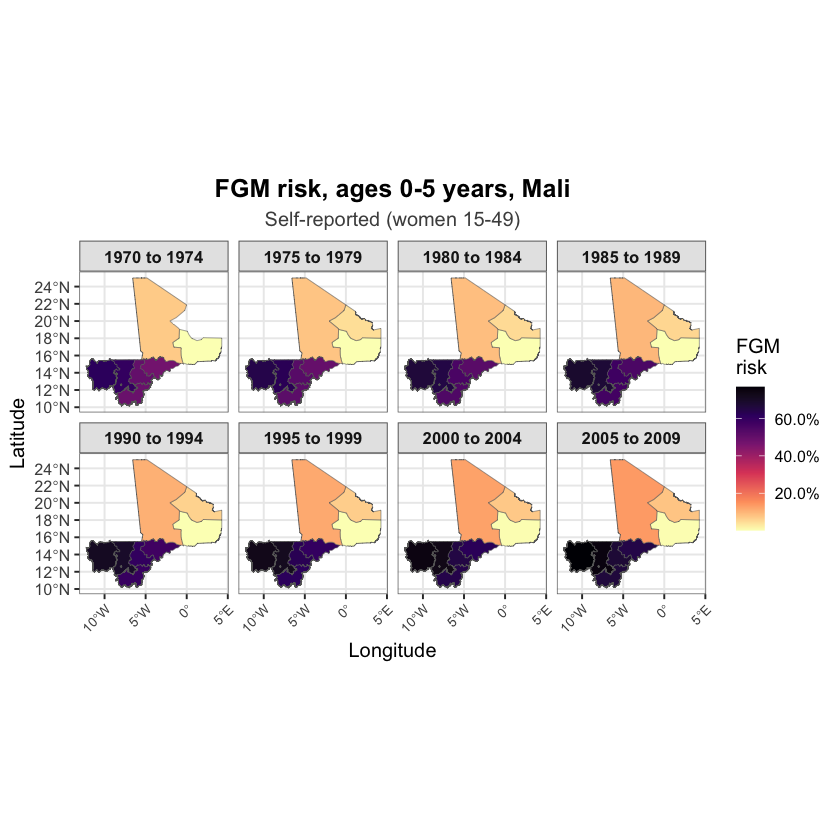

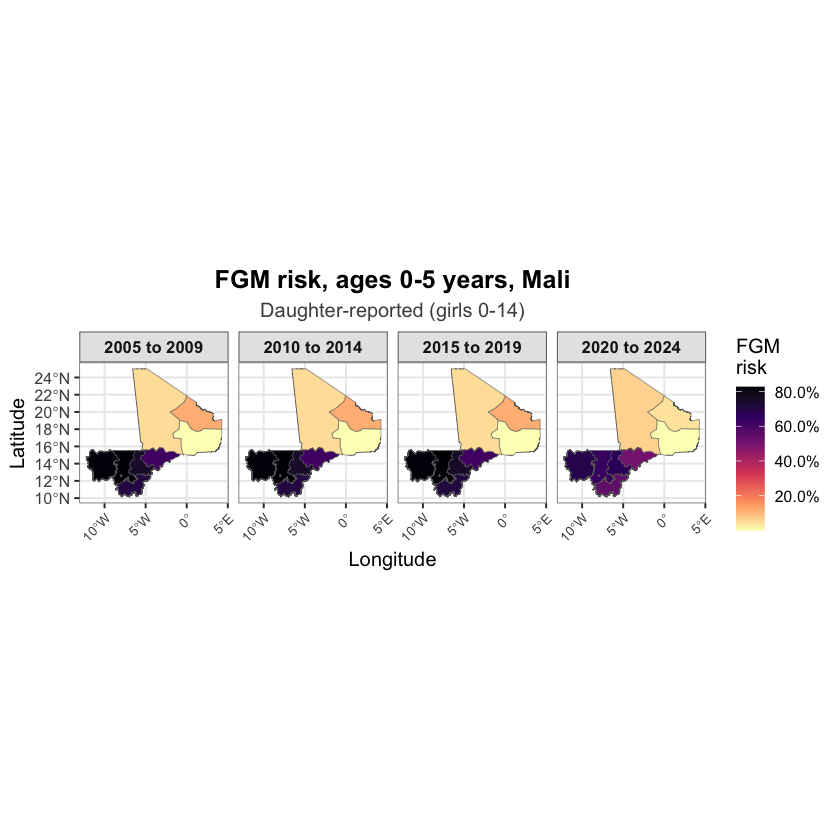

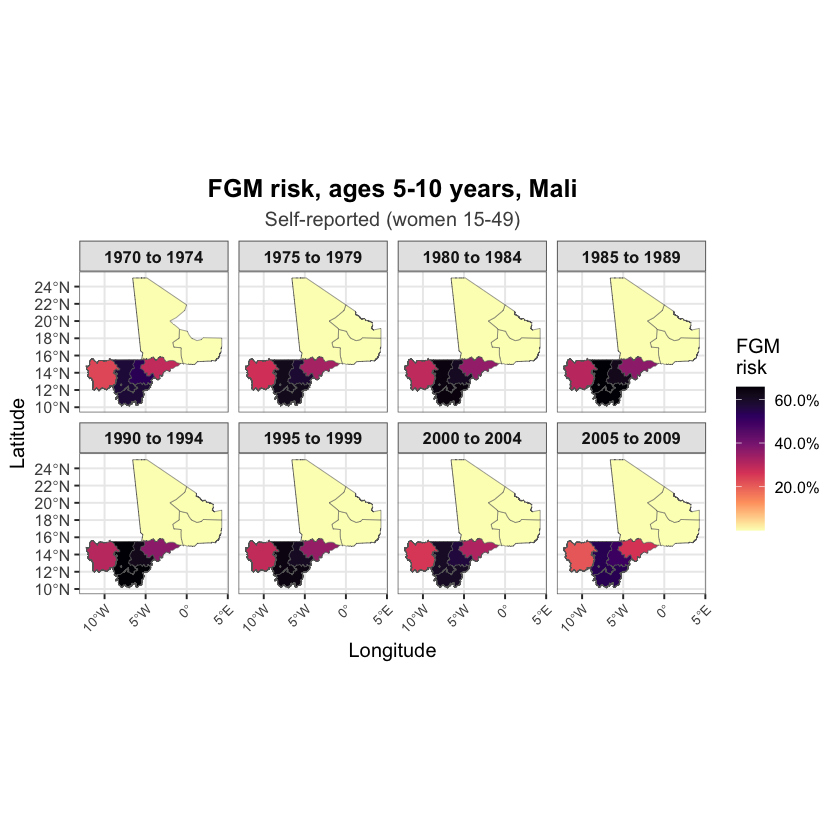

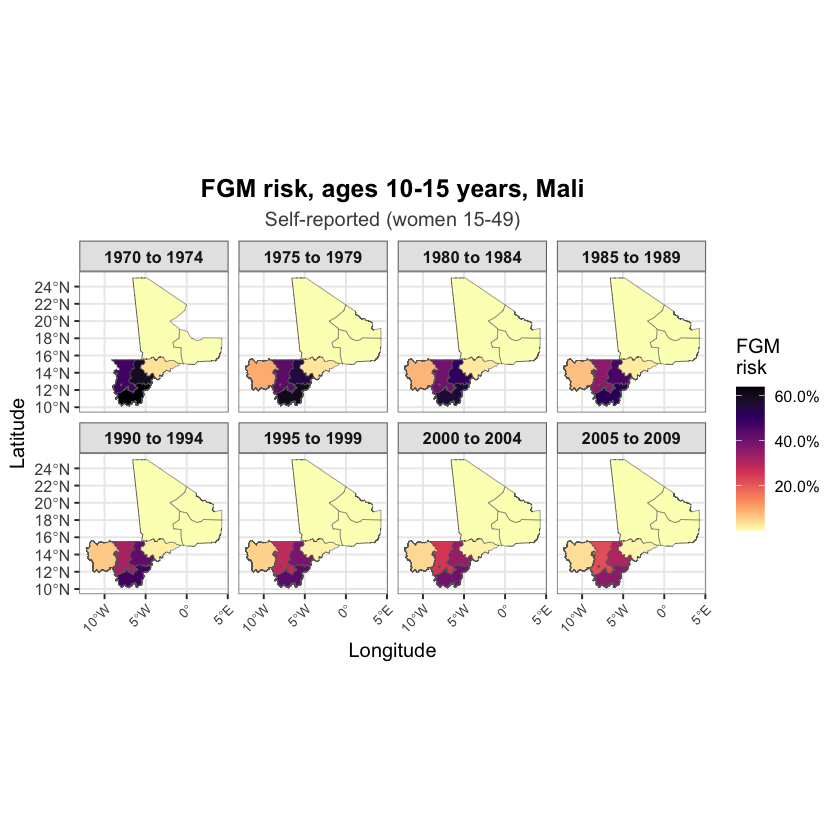

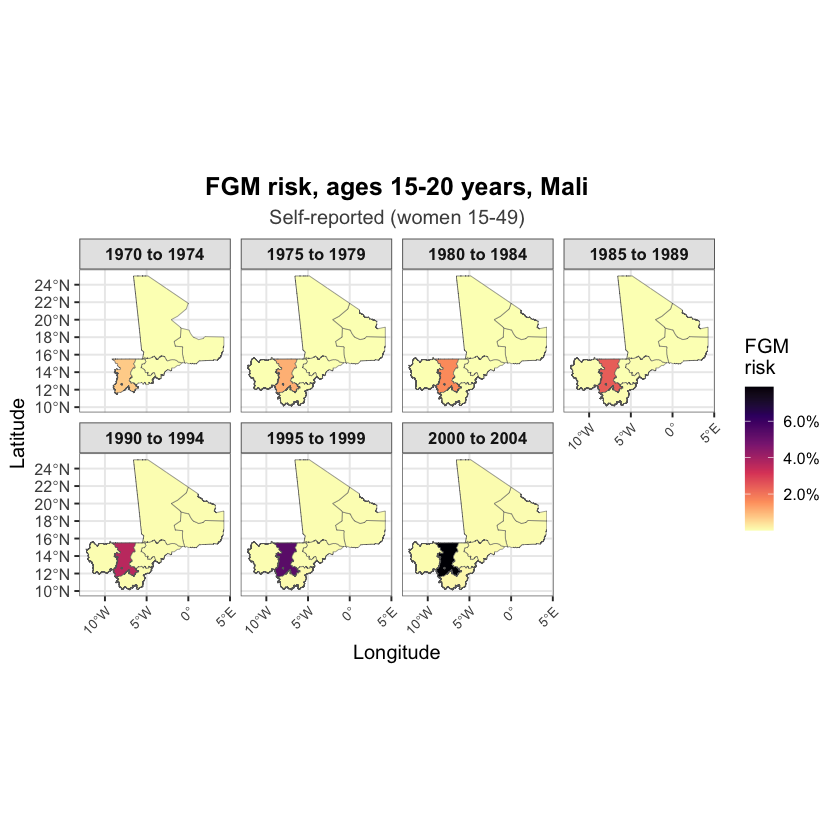

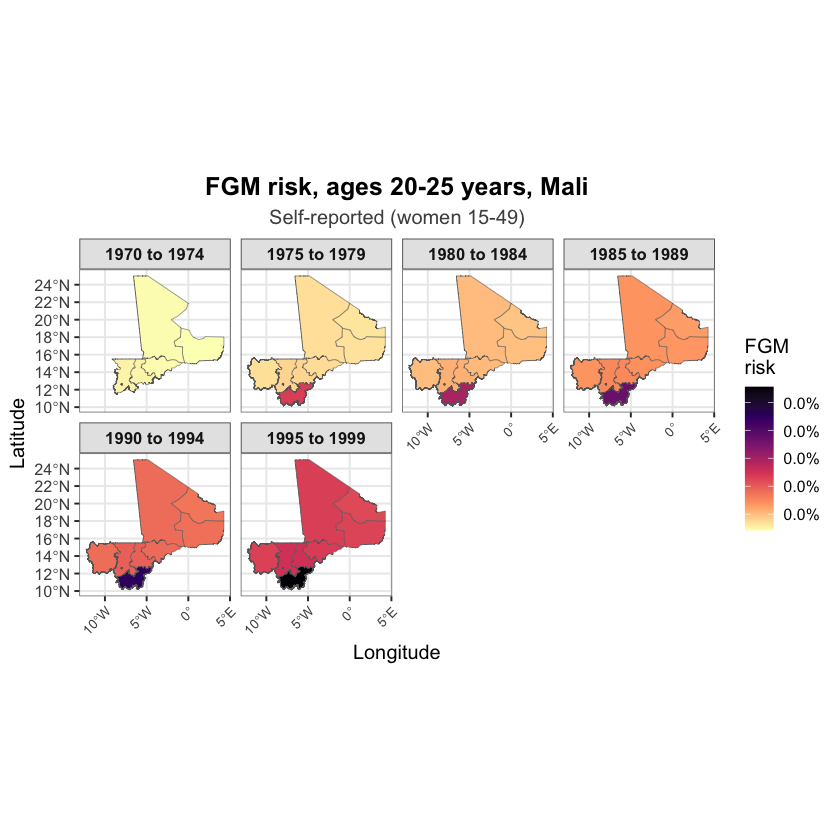

In [66]:
if (run_spatial_model) {
  make_cohort_map_for_band <- function(smoothed_estimates, band_label, source_label) {
    map_data <- boundaries |>
      dplyr::mutate(.region_key = standardize_region(.data[[region_var_shapefile]])) |>
      dplyr::left_join(smoothed_estimates, by = c(".region_key" = "region"))

    ggplot2::ggplot(map_data) +
      ggplot2::geom_sf(ggplot2::aes(fill = smoothed_risk), color = "grey40", linewidth = 0.15) +
      ggplot2::facet_wrap(~birth_cohort, ncol = 4) +
      ggplot2::scale_fill_viridis_c(name = "FGM\nrisk", option = "magma", direction = -1,
                                      labels = scales::percent_format(accuracy = 0.1)) +
      ggplot2::labs(title = paste0("FGM risk, ages ", band_label, " years, ", country_name),
                    subtitle = source_label, x = "Longitude", y = "Latitude") +
      ggplot2::theme_bw(base_size = 12) +
      ggplot2::theme(
        plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
        plot.subtitle = ggplot2::element_text(hjust = 0.5, color = "grey30"),
        strip.text = ggplot2::element_text(face = "bold", size = 10),
        strip.background = ggplot2::element_rect(fill = "grey90", color = "grey40"),
        panel.border = ggplot2::element_rect(color = "grey40", fill = NA, linewidth = 0.4),
        axis.text.x = ggplot2::element_text(angle = 45, hjust = 1, size = 8)
      )
  }

  for (band in age_band_levels) {
    self_band_data <- smoothed_by_band_self |> dplyr::filter(age_band == band)
    if (nrow(self_band_data) > 0) {
      p <- make_cohort_map_for_band(self_band_data, band, "Self-reported (women 15-49)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_self.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }

    daughter_band_data <- smoothed_by_band_daughter |> dplyr::filter(age_band == band)
    if (band == provisional_band) {
      daughter_band_data <- dplyr::bind_rows(daughter_band_data, provisional_daughter_smoothed)
    }
    if (nrow(daughter_band_data) > 0) {
      p <- make_cohort_map_for_band(daughter_band_data, band, "Daughter-reported (girls 0-14)")
      print(p)
      ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_map_ages_", band, "_daughter.png")), plot = p, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
}


## 12A. Geospatial covariates

These additional risk maps retain the preceding map layout, age bands and
reporting-source separation. The original direct-estimate maps and all downstream
Lexis/trend inputs remain unchanged. Results are saved separately under
`Geospatial_Covariates/`.

A survey-weighted discrete-time **logistic hazard** model jointly estimates age,
ethnicity and urban/rural residence effects, a **BYM2 regional effect**, and
**RW2 birth-cohort smoothing**. Separate models are fitted to self-reported and
daughter-reported histories. The linear age term follows Section 8; region is
represented by BYM2 instead of duplicate regional fixed effects. Birth cohort
enters through RW2 rather than a second set of cohort indicators. Covariates
are estimated jointly, not assigned weights based on their effect sizes.

This extends the risk analysis at the annual person-time level. It does not add
individual covariates to the earlier aggregate Gaussian smoothing model or
reuse coefficients from the attitude/prevalence models. Only ethnicity and
residence already present in the risk data are added; education, wealth and
religion are not silently imported from other analysis samples.

For each joint posterior draw, annual hazards are converted into survival
probabilities for each observed ethnicity/residence profile. Survey-weighted
survival is averaged within region and birth cohort, then conditional band risk
is computed as `1 - S(upper)/S(lower)`. The first band includes age-zero events
and starts at survival 1 before age zero, matching the preceding direct-risk
cutpoint convention. Predictions retain each region/cohort's observed covariate
composition; they are model-assisted estimates, not risks standardized to a
common national population or isolated geographic effects.

Only cells shown in the preceding maps are requested. Complete-case follow-up
is checked again; unsupported estimates remain missing. The youngest daughter
cohort is explicitly marked provisional and ends at each region's observed age.
Normalized DHS weights enter the likelihood, and original DHS weights enter
aggregation. Intervals summarize 200 joint pseudo-posterior draws; they do not
fully account for PSU/stratum design uncertainty. Missing covariate exclusions,
model formulas and fixed effects are exported for review.

Implementation references: [INLA likelihood weights](https://www.r-inla.org/learnmore/docs/reference/inla.html)
and [joint posterior sampling](https://www.r-inla.org/learnmore/docs/reference/posterior.sample.html).


In [67]:
# Helpers use separate names so the original risk estimates remain unchanged.
prepare_geo_covariate_risk <- function(events, annual_data, targets, region_keys) {
  covariates <- c("ethnicity", "urban_rural")
  people <- events |>
    dplyr::mutate(region = standardize_region(region),
                  birth_cohort = as.character(birth_cohort)) |>
    dplyr::filter(is.finite(weight), weight > 0) |>
    tidyr::drop_na(dplyr::all_of(covariates), region, birth_cohort)
  if (anyDuplicated(people$id)) stop("Duplicate IDs in geospatial risk input")
  if (!nrow(people)) stop("No complete records for geospatial risk")
  if (any(!people$region %in% region_keys)) stop("Unmatched geospatial risk region")
  cohort_levels <- sort(unique(people$birth_cohort))
  cohort_years <- as.integer(substr(cohort_levels, 1, 4))
  people <- people |>
    dplyr::mutate(region_id = match(region, region_keys),
                  cohort_id = match(birth_cohort, cohort_levels))
  for (v in covariates) people[[v]] <- factor(people[[v]])
  active_covariates <- covariates[vapply(people[covariates], nlevels, integer(1)) > 1L]
  if (length(cohort_levels) < 3L) stop("At least three cohorts are required for RW2")

  annual <- annual_data |>
    dplyr::select(id, age_year, event) |>
    dplyr::inner_join(people |> dplyr::select(id, region_id, cohort_id,
                                              ethnicity, urban_rural, weight), by = "id")
  # Normalize before aggregation: identical predictors AND outcomes have the
  # same Bernoulli likelihood, so summing their weights is exactly equivalent.
  annual <- annual |> dplyr::mutate(pseudo_weight = weight / mean(weight))
  train <- annual |>
    dplyr::group_by(region_id, cohort_id, age_year, ethnicity, urban_rural, event) |>
    dplyr::summarise(pseudo_weight = sum(pseudo_weight), .groups = "drop")

  profiles <- people |>
    dplyr::group_by(region, birth_cohort, region_id, cohort_id, ethnicity, urban_rural) |>
    dplyr::summarise(profile_weight = sum(weight), .groups = "drop") |>
    dplyr::mutate(profile_id = dplyr::row_number())
  support <- people |>
    dplyr::group_by(region, birth_cohort) |>
    dplyr::summarise(complete_case_followup = max(time), n_complete = dplyr::n(),
                     .groups = "drop")
  targets <- targets |>
    dplyr::mutate(region = standardize_region(region),
                  birth_cohort = as.character(birth_cohort),
                  start_age = as.integer(sub("-.*", "", age_band)),
                  end_age = as.integer(sub(".*-", "", age_band))) |>
    dplyr::left_join(support, by = c("region", "birth_cohort")) |>
    dplyr::mutate(stop_age = pmin(observed_to_age, end_age),
                  supported = is.finite(complete_case_followup) &
                    is.finite(stop_age) & stop_age > start_age &
                    stop_age <= complete_case_followup,
                  target_id = dplyr::row_number())
  profiles <- profiles |>
    dplyr::inner_join(targets |> dplyr::filter(supported) |>
                       dplyr::group_by(region, birth_cohort) |>
                       dplyr::summarise(prediction_end = max(stop_age), .groups = "drop"),
                     by = c("region", "birth_cohort"))
  if (!nrow(profiles)) stop("No supported region-cohort profiles for prediction")
  prediction <- profiles |>
    tidyr::uncount(weights = as.integer(prediction_end) + 1L, .id = "age_index") |>
    dplyr::mutate(age_year = age_index - 1L, event = NA_integer_, pseudo_weight = 1) |>
    dplyr::arrange(profile_id, age_year)
  model_data <- dplyr::bind_rows(train, prediction |> dplyr::select(dplyr::all_of(names(train))))
  # Explicit factors keep coding consistent between training and prediction rows.
  for (v in covariates) {
    model_data[[v]] <- factor(model_data[[v]], levels = levels(people[[v]]))
  }
  list(people = people, train = train, prediction = prediction,
       model_data = model_data, targets = targets, active_covariates = active_covariates,
       cohort_years = cohort_years, excluded = nrow(events) - nrow(people),
       annual_n = nrow(annual))
}

geo_covariate_band_risk <- function(eta, prediction, targets) {
  stopifnot(length(eta) == nrow(prediction), all(is.finite(eta)))
  # Stable log(1 - plogis(eta)), including extreme fitted values.
  log_survival_step <- -pmax(eta, 0) - log1p(exp(-abs(eta)))
  survival <- prediction |>
    dplyr::mutate(log_step = log_survival_step) |>
    dplyr::group_by(profile_id) |>
    dplyr::mutate(survival = exp(cumsum(log_step))) |>
    dplyr::ungroup() |>
    dplyr::group_by(region, birth_cohort, age_year) |>
    dplyr::summarise(survival = stats::weighted.mean(survival, profile_weight),
                     .groups = "drop")
  starts <- survival |> dplyr::rename(start_age = age_year, start_survival = survival)
  stops <- survival |> dplyr::rename(stop_age = age_year, stop_survival = survival)
  result <- targets |>
    dplyr::left_join(starts, by = c("region", "birth_cohort", "start_age")) |>
    dplyr::left_join(stops, by = c("region", "birth_cohort", "stop_age")) |>
    dplyr::mutate(
      # Match the original direct-risk convention: S(0-) = 1 for the first
      # band; later bands condition on survival through their lower cutpoint.
      start_survival = dplyr::if_else(start_age == 0L, 1, start_survival),
      risk = dplyr::if_else(supported & is.finite(start_survival) &
                             start_survival > 0 & is.finite(stop_survival),
                           pmin(1, pmax(0, 1 - stop_survival / start_survival)), NA_real_))
  result$risk
}

fit_geo_covariate_risk <- function(prepared, graph, n_draws = 200L, seed = 20260923L) {
  cohort_values <- prepared$cohort_years
  # Actual cohort years retain five-year spacing, even if a cohort is absent.
  model_formula <- stats::as.formula(paste(
    "event ~ age_year", paste(c("", prepared$active_covariates), collapse = " + "),
    "+ f(region_id, model = 'bym2', graph = graph, scale.model = TRUE)",
    "+ f(cohort_id, model = 'rw2', values = cohort_values, scale.model = TRUE, constr = TRUE)"
  ))
  # RW2 index values and values must use the same scale.
  model_data <- prepared$model_data
  model_data$cohort_id <- cohort_values[model_data$cohort_id]
  previous_weight_option <- INLA::inla.getOption("enable.inla.argument.weights")
  INLA::inla.setOption(enable.inla.argument.weights = TRUE)
  on.exit(INLA::inla.setOption(enable.inla.argument.weights = previous_weight_option), add = TRUE)
  fit <- INLA::inla(
    model_formula, family = "binomial", data = model_data,
    Ntrials = rep(1L, nrow(model_data)), weights = model_data$pseudo_weight,
    control.predictor = list(compute = TRUE, link = 1),
    control.compute = list(config = TRUE),
    control.inla = list(control.vb = list(enable = FALSE))
  )
  # Transform complete joint posterior predictors before aggregating; do not
  # combine marginal interval endpoints or average annual hazards across people.
  set.seed(seed)
  prediction_indices <- nrow(prepared$train) + seq_len(nrow(prepared$prediction))
  draw_risks <- matrix(NA_real_, nrow(prepared$targets), n_draws)
  for (first in seq.int(1L, n_draws, by = 20L)) {
    last <- min(n_draws, first + 19L)
    samples <- INLA::inla.posterior.sample(last - first + 1L, fit,
                                          use.improved.mean = FALSE, skew.corr = FALSE)
    for (j in seq_along(samples)) {
      latent <- samples[[j]]$latent
      all_predictor_rows <- grep("^Predictor:", rownames(latent))
      predictor_numbers <- suppressWarnings(as.integer(sub("^Predictor:", "",
        rownames(latent)[all_predictor_rows])))
      predictor_rows <- all_predictor_rows[match(prediction_indices, predictor_numbers)]
      if (anyNA(predictor_rows)) stop("Posterior predictor rows do not match prediction data")
      draw_risks[, first + j - 1L] <- geo_covariate_band_risk(
        as.numeric(latent[predictor_rows, 1L]), prepared$prediction, prepared$targets)
    }
  }
  safe_quantile <- function(x, p) {
    if (all(is.na(x))) NA_real_ else unname(stats::quantile(x, p, na.rm = TRUE))
  }
  estimates <- prepared$targets |>
    dplyr::mutate(
      adjusted_risk = rowMeans(draw_risks),
      lower_ci = apply(draw_risks, 1L, safe_quantile, p = 0.025),
      upper_ci = apply(draw_risks, 1L, safe_quantile, p = 0.975),
      estimate_status = dplyr::case_when(
        !supported ~ "Insufficient complete-case follow-up",
        is_provisional ~ "Provisional: incomplete age band",
        TRUE ~ "Completed age band"))
  list(estimates = estimates, fixed_effects = fit$summary.fixed,
       formula = paste(deparse(model_formula), collapse = " "),
       excluded = prepared$excluded, annual_n = prepared$annual_n)
}


In [68]:
if (run_spatial_model) {
  geo_cov_required <- c("INLA", "sf", "spdep")
  geo_cov_missing <- geo_cov_required[
    !vapply(geo_cov_required, requireNamespace, logical(1), quietly = TRUE)]
  if (length(geo_cov_missing)) stop("Geospatial covariates requires: ",
                                  paste(geo_cov_missing, collapse = ", "))
  geo_cov_output_dir <- file.path(output_dir, "Geospatial_Covariates")
  dir.create(geo_cov_output_dir, recursive = TRUE, showWarnings = FALSE)
  geo_cov_draws <- 200L
  geo_cov_results <- list()
  geo_cov_audit <- list()

  for (geo_cov_source in c("self", "daughter")) {
    geo_cov_direct <- if (geo_cov_source == "self") full_risk_self else full_risk_daughter
    geo_cov_existing <- if (geo_cov_source == "self") smoothed_by_band_self else smoothed_by_band_daughter
    # Match the completed region/cohort/age-band cells in the original maps.
    geo_cov_targets <- geo_cov_existing |>
      dplyr::select(region, birth_cohort, age_band) |>
      dplyr::distinct() |>
      dplyr::left_join(geo_cov_direct |>
                        dplyr::select(region, birth_cohort, age_band, observed_to_age),
                      by = c("region", "birth_cohort", "age_band")) |>
      dplyr::mutate(is_provisional = FALSE)
    if (geo_cov_source == "daughter" && nrow(provisional_daughter_smoothed) > 0L) {
      geo_cov_targets <- dplyr::bind_rows(
        geo_cov_targets,
        provisional_daughter_smoothed |>
          dplyr::transmute(region, birth_cohort, age_band, observed_to_age,
                           is_provisional = TRUE))
    }
    if (!nrow(geo_cov_targets)) next
    geo_cov_prepared <- prepare_geo_covariate_risk(
      fgm_events |> dplyr::filter(record_type == geo_cov_source),
      person_time |> dplyr::filter(record_type == geo_cov_source),
      geo_cov_targets, boundary_region_keys)
    cat("Geospatial covariates:", geo_cov_source, "--", nrow(geo_cov_prepared$people),
        "histories;", geo_cov_prepared$excluded, "excluded for missing covariates/invalid weights\n")
    geo_cov_result <- fit_geo_covariate_risk(
      geo_cov_prepared, adjacency_matrix, n_draws = geo_cov_draws,
      seed = if (geo_cov_source == "self") 20260923L else 20260924L)
    geo_cov_results[[geo_cov_source]] <- geo_cov_result$estimates |>
      dplyr::mutate(record_type = geo_cov_source)
    geo_cov_audit[[geo_cov_source]] <- tibble::tibble(
      record_type = geo_cov_source, n_histories = nrow(geo_cov_prepared$people),
      excluded = geo_cov_prepared$excluded, annual_rows = geo_cov_prepared$annual_n,
      grouped_likelihood_rows = nrow(geo_cov_prepared$train), posterior_draws = geo_cov_draws,
      formula = geo_cov_result$formula)
    readr::write_csv(geo_cov_results[[geo_cov_source]], file.path(geo_cov_output_dir,
      paste0(country_iso3, "_covariate_adjusted_risk_", geo_cov_source, ".csv")))
    readr::write_csv(tibble::rownames_to_column(as.data.frame(geo_cov_result$fixed_effects), "term"),
      file.path(geo_cov_output_dir,
                paste0(country_iso3, "_risk_covariate_fixed_effects_", geo_cov_source, ".csv")))
  }
  readr::write_csv(dplyr::bind_rows(geo_cov_audit),
                   file.path(geo_cov_output_dir, paste0(country_iso3, "_risk_covariate_model_audit.csv")))
} else {
  message("Geospatial covariates skipped: survey-region boundary file unavailable")
}


Geospatial covariates: self -- 16995 histories; 0 excluded for missing covariates/invalid weights


Warning message in inla.matchOption(option, valid.opt, several.ok = TRUE):
"Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning, inla.call"
Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
"Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmeshe

Geospatial covariates: daughter -- 17512 histories; 0 excluded for missing covariates/invalid weights


Warning message in inla.matchOption(option, valid.opt, several.ok = TRUE):
"Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmesher.evolution.verbosity, INLAjoint.features, numa, disable.values.warning, inla.call"
Warning message in inla.matchOption(option, valid.opt, several.ok = FALSE):
"Unknown or ambiguous INLA option 'enable.inla.argument.weights' will be ignored. Valid options are: inla.call, inla.arg, num.threads, blas.num.threads, smtp, safe, keep, verbose, save.memory, internal.opt, working.directory, silent, debug, show.warning.graph.file, scale.model.default, short.summary, inla.timeout, inla.mode, malloc.lib, fmesher.evolution, fmesher.evolution.warn, fmeshe

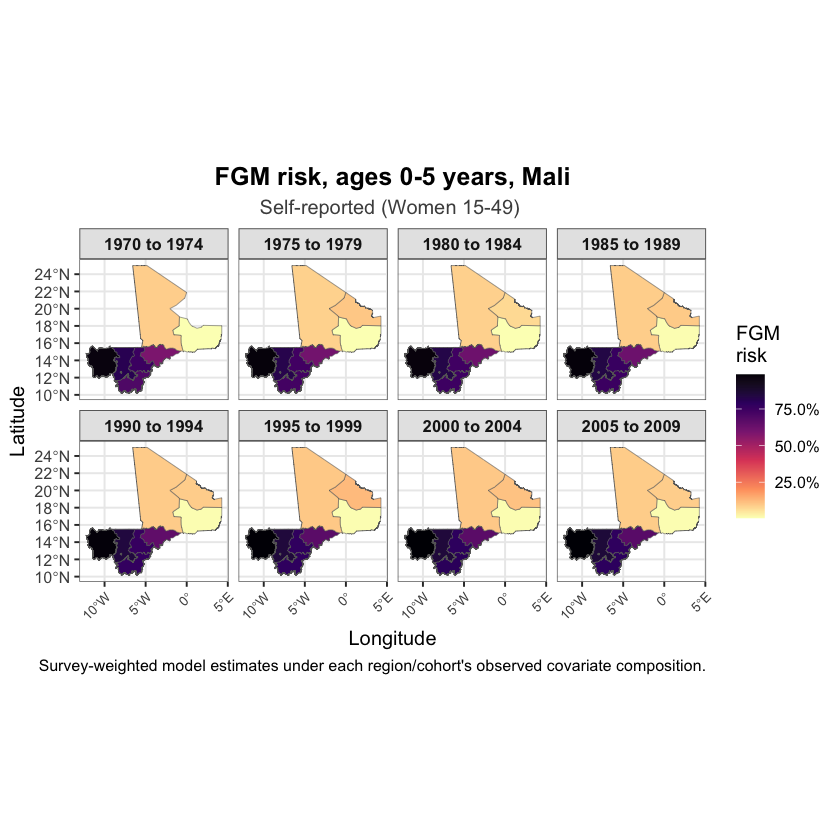

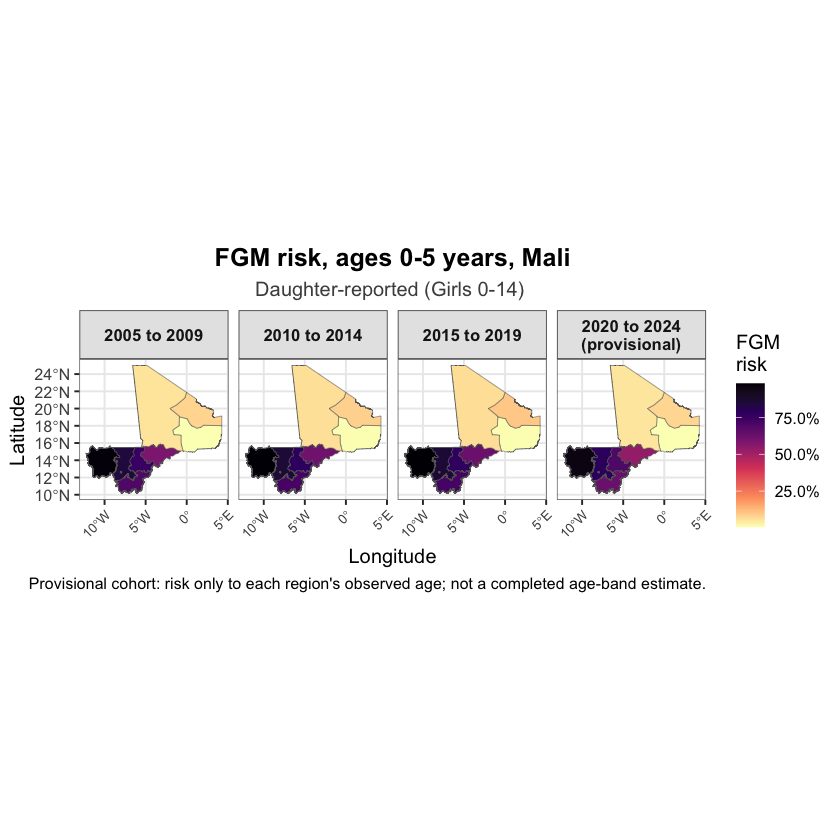

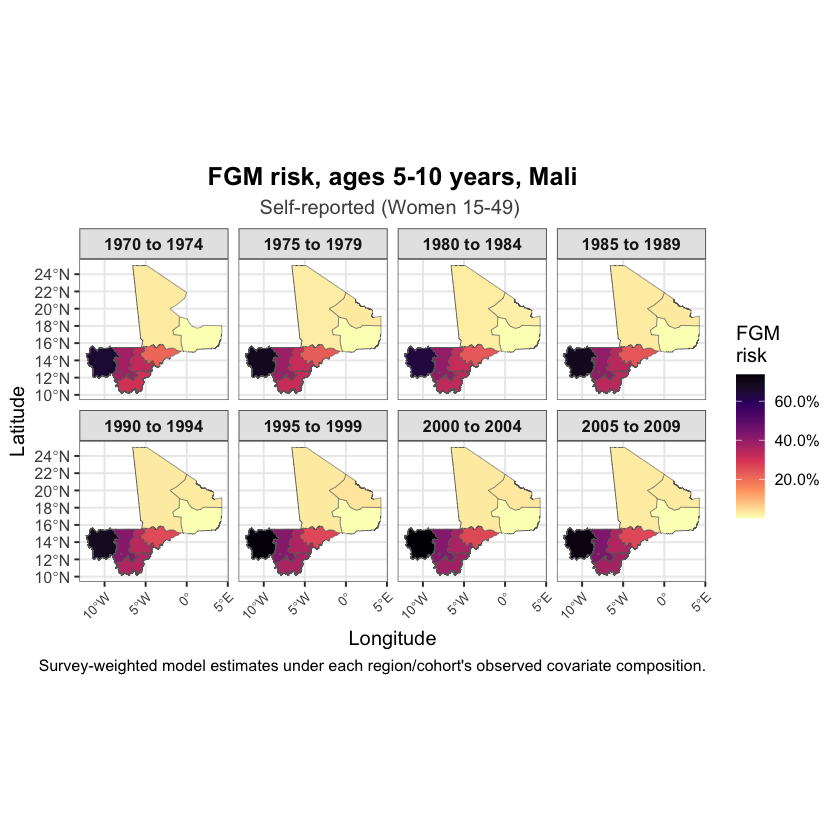

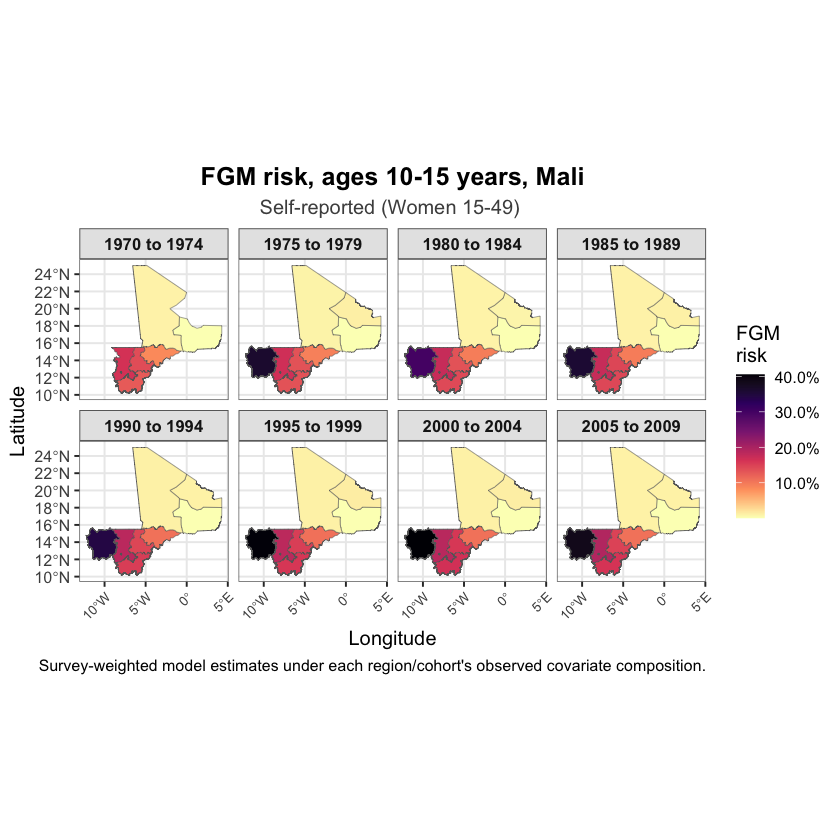

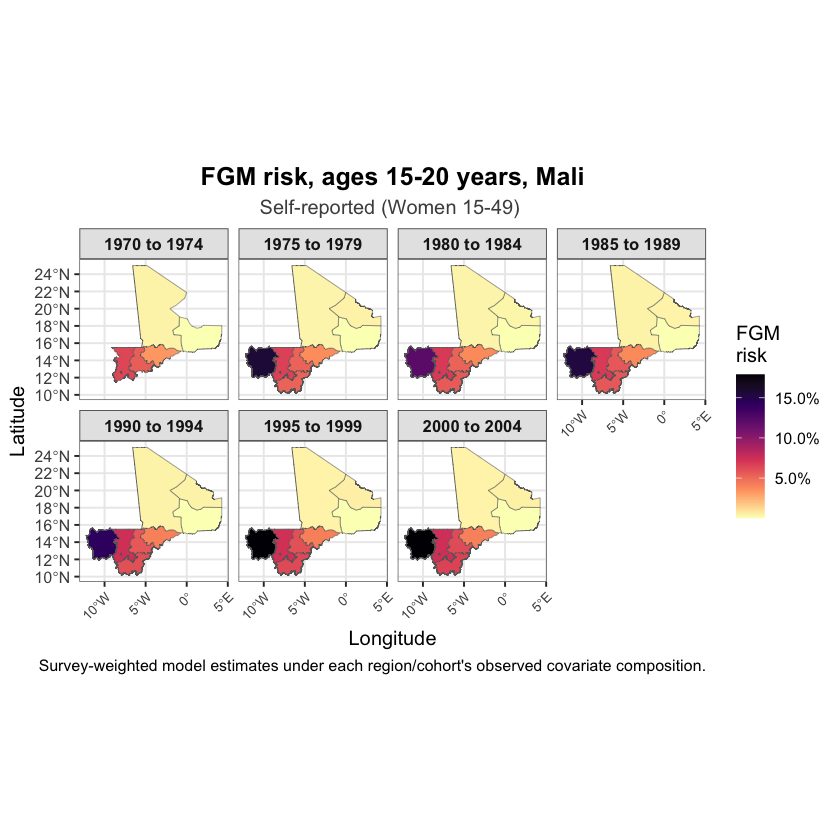

Covariate-adjusted risk maps and estimates: ../03_Outputs/MLI/Geospatial_Covariates 


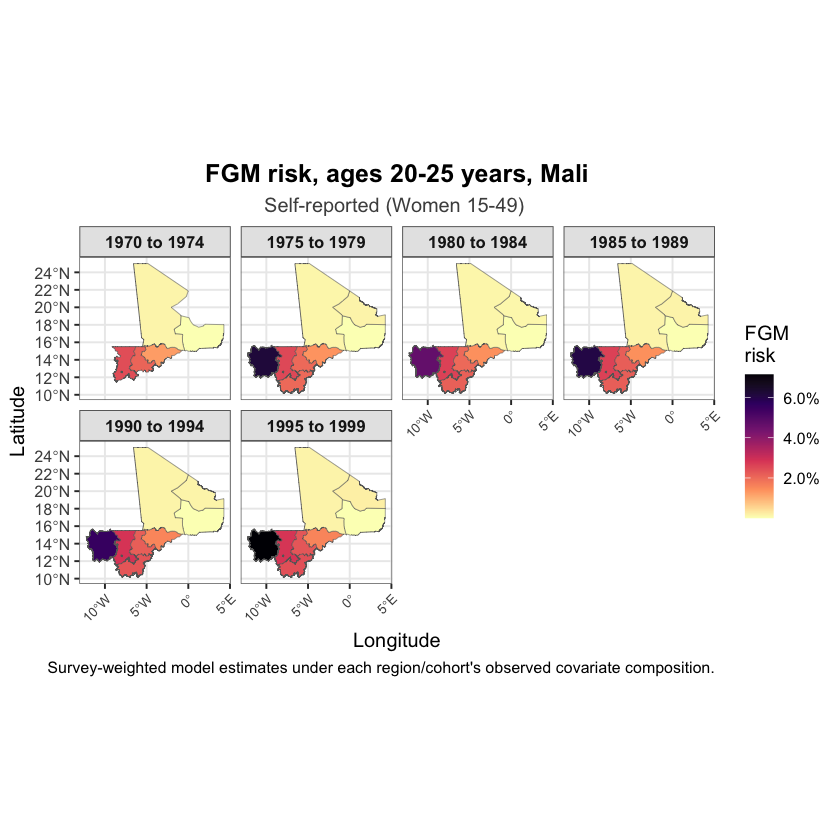

In [80]:
if (run_spatial_model) {
  for (geo_cov_band in age_band_levels) {
    for (geo_cov_source in names(geo_cov_results)) {
      geo_cov_map_data <- geo_cov_results[[geo_cov_source]] |>
        dplyr::filter(age_band == geo_cov_band) |>
        dplyr::mutate(
          smoothed_risk = adjusted_risk,
          birth_cohort = dplyr::if_else(is_provisional,
                                        paste0(birth_cohort, "\n(provisional)"), birth_cohort),
          birth_cohort = factor(birth_cohort, levels = sort(unique(birth_cohort))))
      if (!nrow(geo_cov_map_data)) next
      geo_cov_source_label <- if (geo_cov_source == "self")
        "Self-reported (Women 15-49)" else "Daughter-reported (Girls 0-14)"
      # Reuse the exact original map function: four cohort panels per row,
      # reversed magma palette, boundaries, axes, typography and 12 x 8 export.
      geo_cov_plot <- make_cohort_map_for_band(
        geo_cov_map_data, geo_cov_band,
        paste0(geo_cov_source_label, " ")) +
        ggplot2::labs(
          title = paste0("FGM risk, ages ", geo_cov_band,
                         " years, ", country_name),
          caption = if (any(geo_cov_map_data$is_provisional))
            "Provisional cohort: risk only to each region's observed age; not a completed age-band estimate."
          else "Survey-weighted model estimates under each region/cohort's observed covariate composition.")
      print(geo_cov_plot)
      ggplot2::ggsave(file.path(geo_cov_output_dir,
        paste0(country_iso3, "_covariate_adjusted_map_ages_", geo_cov_band, "_", geo_cov_source, ".png")),
        plot = geo_cov_plot, width = 12, height = 8, dpi = 300, bg = "white")
    }
  }
  cat("Covariate-adjusted risk maps and estimates:", geo_cov_output_dir, "\n")
}


## 13. Lexis heatmap

A single Lexis surface per country shows age, period, and cohort patterns together, replacing the several separate Kaplan Meier line charts the original presentation used, following section 2.4 of the improved methodology document.

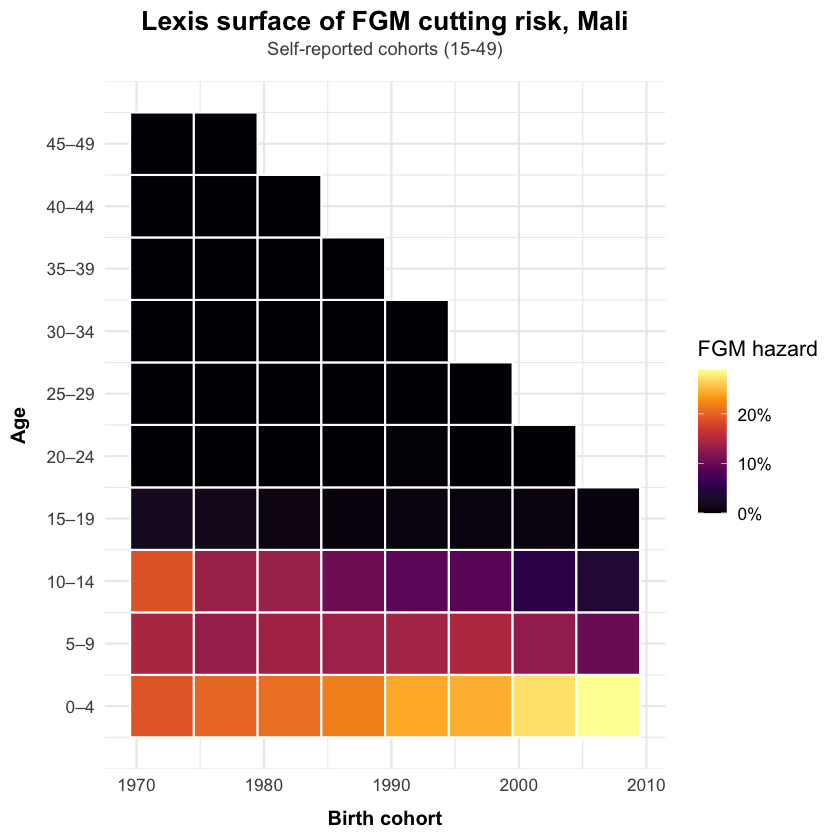

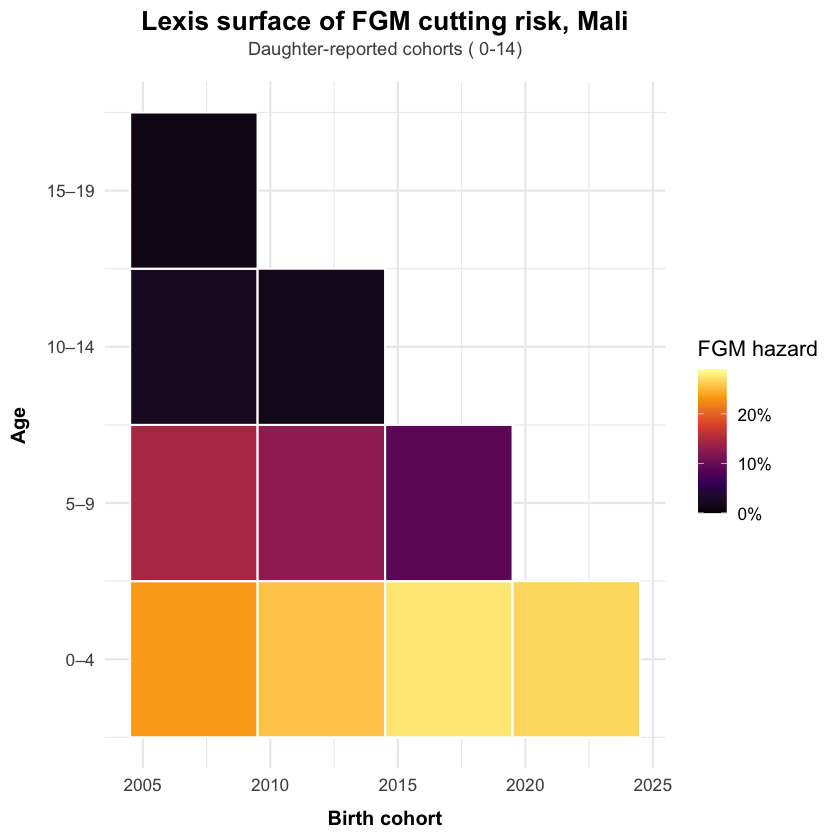

In [79]:
build_lexis_grid <- function(data) {
  data |>
    dplyr::mutate(
      age_band = cut(age_year, breaks = seq(0, 50, by = 5), right = FALSE),
      age_band_mid = as.numeric(stringr::str_extract(age_band, "[0-9]+")) + 2.5
    ) |>
    dplyr::group_by(age_band_mid, cohort_mid) |>
    dplyr::summarise(hazard = weighted.mean(event, weight, na.rm = TRUE), .groups = "drop")
}

lexis_grid_self     <- build_lexis_grid(cohort_numeric |> dplyr::filter(record_type == "self"))
lexis_grid_daughter <- build_lexis_grid(cohort_numeric |> dplyr::filter(record_type == "daughter"))
hazard_limits <- range(c(lexis_grid_self$hazard, lexis_grid_daughter$hazard), na.rm = TRUE)

build_lexis_plot <- function(lexis_grid, subtitle_label, file_suffix) {
  p <- ggplot2::ggplot(lexis_grid, ggplot2::aes(x = cohort_mid, y = age_band_mid, fill = hazard)) +
    ggplot2::geom_tile(width = 5, height = 5, color = "white", linewidth = 0.6) +
    ggplot2::scale_fill_viridis_c(name = "FGM hazard", option = "inferno", labels = scales::percent,
                                    limits = hazard_limits, oob = scales::squish) +
    ggplot2::scale_y_continuous(breaks = seq(2.5, 47.5, by = 5),
                                  labels = paste0(seq(0, 45, by = 5), "\u2013", seq(4, 49, by = 5))) +
    ggplot2::labs(
      title = paste("Lexis surface of FGM cutting risk,", country_name),
      subtitle = subtitle_label, x = "Birth cohort", y = "Age"
    ) +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(
      plot.title = ggplot2::element_text(face = "bold", hjust = 0.5, size = 16, margin = ggplot2::margin(b = 4)),
      plot.subtitle = ggplot2::element_text(hjust = 0.5, size = 11, color = "grey30", margin = ggplot2::margin(b = 14)),
      axis.title.x = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(t = 10)),
      axis.title.y = ggplot2::element_text(face = "bold", size = 12, margin = ggplot2::margin(r = 10))
    )
  print(p)
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_lexis_heatmap_", file_suffix, ".png")),
                   plot = p, width = 8, height = 6)
  p
}

lexis_plot_self     <- build_lexis_plot(lexis_grid_self, "Self-reported cohorts (15-49)", "self")
lexis_plot_daughter <- build_lexis_plot(lexis_grid_daughter, "Daughter-reported cohorts ( 0-14)", "daughter")


# Line Graphs

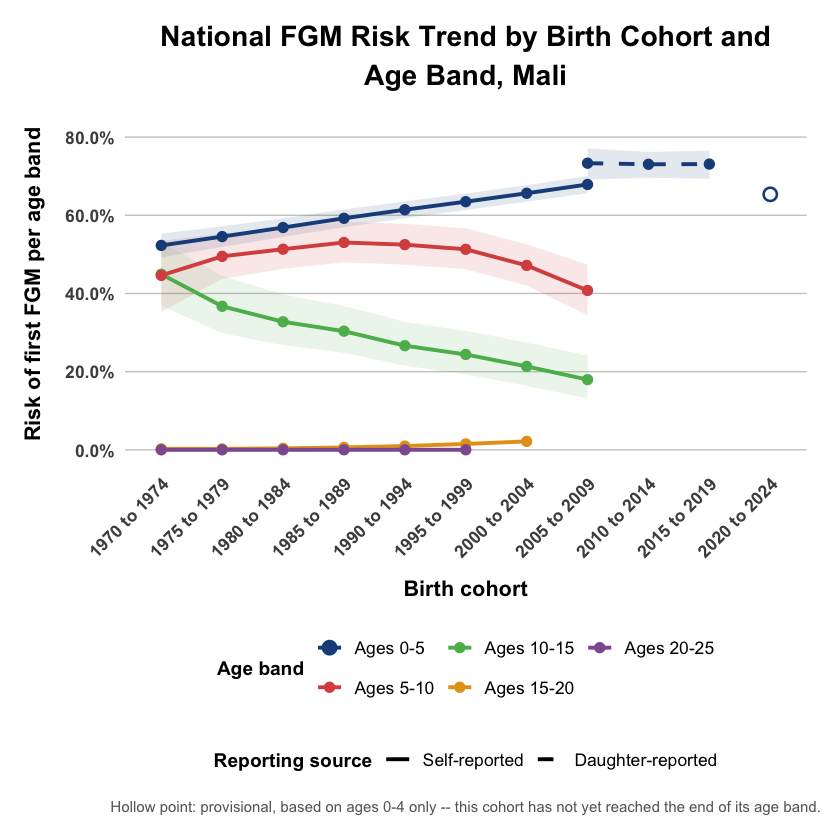

In [71]:
# National average FGM risk trend by birth cohort, all age bands together
# on one set of axes -- color = age band, linetype = reporting source.
# Weighted by each region x cohort cell's survey-weighted population size.

trend_all_bands <- dplyr::bind_rows(
  smoothed_by_band_self |>
    dplyr::group_by(birth_cohort, age_band) |>
    dplyr::summarise(
      mean_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE),
      lower_ci  = weighted.mean(lower_ci, w = sum_weight, na.rm = TRUE),
      upper_ci  = weighted.mean(upper_ci, w = sum_weight, na.rm = TRUE),
      .groups = "drop"
    ) |>
    dplyr::mutate(record_type = "Self-reported"),
  smoothed_by_band_daughter |>
    dplyr::group_by(birth_cohort, age_band) |>
    dplyr::summarise(
      mean_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE),
      lower_ci  = weighted.mean(lower_ci, w = sum_weight, na.rm = TRUE),
      upper_ci  = weighted.mean(upper_ci, w = sum_weight, na.rm = TRUE),
      .groups = "drop"
    ) |>
    dplyr::mutate(record_type = "Daughter-reported")
) |>
  dplyr::mutate(
    birth_cohort = as.character(birth_cohort),
    cohort_start = as.numeric(sub(" .*", "", birth_cohort))
  ) |>
  dplyr::arrange(cohort_start) |>
  dplyr::mutate(
    birth_cohort = factor(birth_cohort, levels = unique(birth_cohort)),
    record_type  = factor(record_type, levels = c("Self-reported", "Daughter-reported")),
    age_band     = factor(age_band, levels = c("0-5", "5-10", "10-15", "15-20", "20-25"),
                            labels = c("Ages 0-5", "Ages 5-10", "Ages 10-15", "Ages 15-20", "Ages 20-25"))
  )

# National-only provisional estimate for the most recent, not-yet-complete
# cohort. Deliberately unsmoothed and national-level: too little follow-up
# per state to spatially smooth yet, but it's real information (e.g. infant
# cutting already observed) that would otherwise be silently dropped.
national_provisional_point <- function(record_data, record_label) {
  cohort_levels <- levels(record_data$birth_cohort)
  latest_cohort <- tail(cohort_levels[cohort_levels %in% as.character(record_data$birth_cohort)], 1)
  cell_data <- record_data |> dplyr::filter(birth_cohort %in% latest_cohort)
  max_observed <- max(cell_data$time, na.rm = TRUE)
  if (max_observed >= 5) return(tibble::tibble())
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = cell_data, nest = TRUE)
  # se=TRUE dropped -- verified it takes 19+ sec for ~2,500 rows and doesn't
  # even finish within a minute for ~8,000 rows, while this function only
  # ever reads the point estimate (no CI is shown for these provisional
  # points), so the variance computation was pure wasted cost.
  fit_r <- survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = design)
  before <- which(fit_r$time <= max_observed)
  surv_obs <- if (length(before) == 0) 1 else fit_r$surv[max(before)]
  tibble::tibble(
    birth_cohort = as.character(latest_cohort),
    mean_risk = 1 - surv_obs, observed_to_age = max_observed,
    record_type = record_label
  )
}

provisional_points <- dplyr::bind_rows(
  national_provisional_point(fgm_events |> dplyr::filter(record_type == "self"),     "Self-reported"),
  national_provisional_point(fgm_events |> dplyr::filter(record_type == "daughter"), "Daughter-reported")
)

# FIX: trend_all_bands's birth_cohort levels stop at the last cohort present
# in the spatially-smoothed data (e.g. "2015 to 2019"), since the provisional
# cohort was deliberately excluded from smoothing. Forcing provisional_points
# onto that same, too-short level set turned "2020 to 2024" into NA (factor()
# maps any value outside its level list to NA) -- which is exactly the extra
# "NA" tick that showed up on the x-axis. Fix: build one shared, chronologically
# sorted level set from BOTH data frames, and apply it to both.
if (nrow(provisional_points) > 0) {
  cohort_levels_combined <- union(levels(trend_all_bands$birth_cohort), unique(provisional_points$birth_cohort))
  cohort_levels_combined <- cohort_levels_combined[order(as.numeric(sub(" .*", "", cohort_levels_combined)))]

  trend_all_bands <- trend_all_bands |>
    dplyr::mutate(birth_cohort = factor(as.character(birth_cohort), levels = cohort_levels_combined))

  provisional_points <- provisional_points |>
    dplyr::mutate(
      birth_cohort = factor(birth_cohort, levels = cohort_levels_combined),
      age_band     = factor("Ages 0-5", levels = levels(trend_all_bands$age_band)),
      record_type  = factor(record_type, levels = levels(trend_all_bands$record_type))
    )
}

y_max <- max(trend_all_bands$upper_ci, provisional_points$mean_risk, na.rm = TRUE)
y_limit <- min(1, ceiling(y_max * 1.1 * 100) / 100)

age_band_colors <- c(
  "Ages 0-5"    = "#1D4E89",
  "Ages 5-10"   = "#D9534F",
  "Ages 10-15"  = "#5CB85C",
  "Ages 15-20"  = "#E5A11C",
  "Ages 20-25"  = "#8E5DA0"
)

trend_plot_all_bands <- ggplot2::ggplot(
  trend_all_bands,
  ggplot2::aes(x = birth_cohort, y = mean_risk, color = age_band, linetype = record_type,
               group = interaction(age_band, record_type))
) +
  ggplot2::geom_ribbon(
    ggplot2::aes(ymin = lower_ci, ymax = upper_ci, fill = age_band, group = interaction(age_band, record_type)),
    alpha = 0.12, color = NA, show.legend = FALSE, na.rm = TRUE
  ) +
  ggplot2::geom_line(linewidth = 1.1, na.rm = TRUE) +
  ggplot2::geom_point(size = 2.4, na.rm = TRUE) +
  ggplot2::geom_point(
    data = provisional_points,
    ggplot2::aes(x = birth_cohort, y = mean_risk, color = age_band, shape = record_type),
    size = 3, stroke = 1.1, fill = NA, inherit.aes = FALSE
  ) +
  ggplot2::scale_color_manual(values = age_band_colors, name = "Age band") +
  ggplot2::scale_fill_manual(values = age_band_colors, guide = "none") +
  ggplot2::scale_linetype_manual(values = c("Self-reported" = "solid", "Daughter-reported" = "dashed"),
                                   name = "Reporting source") +
  ggplot2::scale_shape_manual(values = c("Self-reported" = 1, "Daughter-reported" = 1), guide = "none") +
  ggplot2::scale_y_continuous(
    labels = scales::percent_format(accuracy = 0.1),
    limits = c(0, y_limit),
    breaks = scales::pretty_breaks(n = 6)
  ) +
  ggplot2::labs(
    title = stringr::str_wrap(
      paste("National FGM Risk Trend by Birth Cohort and Age Band,", country_name),
      width = 45
    ),
    x = "Birth cohort", y = "Risk of first FGM per age band",
    caption = if (nrow(provisional_points) > 0) {
      paste0("Hollow point: provisional, based on ages 0-", max(provisional_points$observed_to_age),
             " only -- this cohort has not yet reached the end of its age band.")
    } else NULL
  ) +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 17, hjust = 0.5, lineheight = 1.15, margin = ggplot2::margin(b = 6)),
    plot.caption = ggplot2::element_text(size = 9, color = "grey40", hjust = 0.5, margin = ggplot2::margin(t = 10)),
    axis.title.x = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(t = 12)),
    axis.title.y = ggplot2::element_text(face = "bold", size = 13, margin = ggplot2::margin(r = 12)),
    axis.text.x = ggplot2::element_text(face = "bold", angle = 45, hjust = 1, vjust = 1, size = 10.5),
    axis.text.y = ggplot2::element_text(face = "bold", size = 10.5),
    legend.position = "bottom",
    legend.box = "vertical",
    legend.title = ggplot2::element_text(face = "bold", size = 11.5),
    legend.text = ggplot2::element_text(size = 10.5),
    panel.grid.major.x = ggplot2::element_blank(),
    panel.grid.minor = ggplot2::element_blank(),
    panel.grid.major.y = ggplot2::element_line(color = "grey80", linewidth = 0.4),
    plot.margin = ggplot2::margin(t = 15, r = 20, b = 15, l = 15)
  ) +
  ggplot2::guides(
    color = ggplot2::guide_legend(order = 1, nrow = 2),
    linetype = ggplot2::guide_legend(order = 2)
  )

print(trend_plot_all_bands)

ggplot2::ggsave(
  filename = file.path(output_dir, paste0(country_iso3, "_national_risk_trend_all_bands_combined.png")),
  plot = trend_plot_all_bands, width = 12, height = 8, dpi = 300, bg = "white"
)


Use the Mali estimates generated in the preceding sections to describe cohort change, age at cutting, and survey-region variation. Self-reported and daughter-reported histories should be compared only over common observed ages. The youngest daughter cohorts have incomplete follow-up and must not be interpreted as completed lifetime risk. Regional estimates with small effective samples or wide intervals require additional caution.

## 14. Change point analysis

Identify the birth cohort or calendar year at which a country's incidence trend meaningfully changed, replacing the qualitative declining versus not declining read used in the original presentation, following section 3 of the improved methodology document.

# A tibble: 1 x 4
  country basis                      changepoint_detected estimated_change_coh~1
  <chr>   <chr>                      <lgl>                                 <dbl>
1 Mali    self-reported cohorts only FALSE                                    NA
# i abbreviated name: 1: estimated_change_cohort


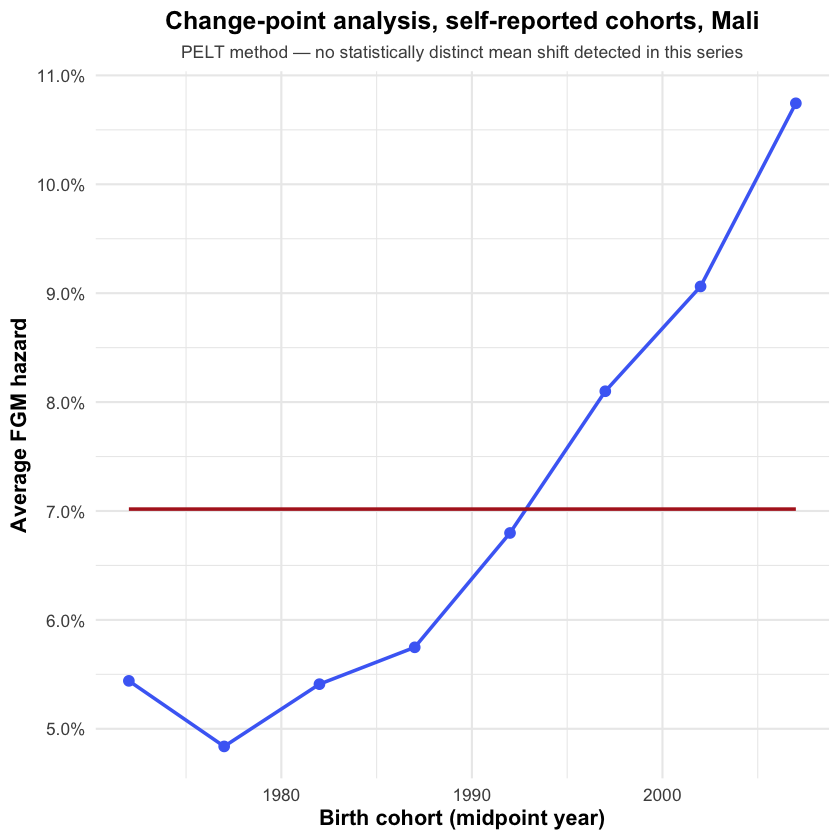

In [72]:
if (run_change_point) {
  library(changepoint)

  cohort_series <- lexis_grid_self |>
    dplyr::group_by(cohort_mid) |>
    dplyr::summarise(mean_hazard = mean(hazard, na.rm = TRUE)) |>
    dplyr::arrange(cohort_mid)

  cpt_result <- changepoint::cpt.mean(cohort_series$mean_hazard, method = "PELT")
  n_segments <- length(cpt_result@cpts)

  change_point_estimate <- tibble::tibble(
    country = country_name,
    basis = "self-reported cohorts only",
    changepoint_detected = n_segments > 1,
    estimated_change_cohort = if (n_segments > 1) cohort_series$cohort_mid[cpt_result@cpts[1]] else NA_real_
  )
  readr::write_csv(change_point_estimate, file.path(output_dir, paste0(country_iso3, "_change_point.csv")))
  print(change_point_estimate)

  segment_bounds <- c(0, cpt_result@cpts)
  cohort_series_plot <- cohort_series |>
    dplyr::mutate(index = dplyr::row_number(),
                   segment = cut(index, breaks = segment_bounds, labels = FALSE)) |>
    dplyr::group_by(segment) |>
    dplyr::mutate(segment_mean = mean(mean_hazard)) |>
    dplyr::ungroup()

  subtitle_text <- if (n_segments > 1) {
    paste("PELT method \u2014 detected shift after the",
          cohort_series_plot$cohort_mid[cpt_result@cpts[1]], "cohort (red line: segment means)")
  } else {
    "PELT method \u2014 no statistically distinct mean shift detected in this series"
  }

  cpt_plot <- ggplot2::ggplot(cohort_series_plot, ggplot2::aes(x = cohort_mid, y = mean_hazard)) +
    ggplot2::geom_line(color = "#4C6EF5", linewidth = 1) +
    ggplot2::geom_point(size = 2.5, color = "#4C6EF5") +
    ggplot2::geom_line(ggplot2::aes(y = segment_mean, group = segment), color = "firebrick", linewidth = 1) +
    ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
    ggplot2::labs(
      title = paste("Change-point analysis, self-reported cohorts,", country_name),
      subtitle = subtitle_text,
      x = "Birth cohort (midpoint year)", y = "Average FGM hazard"
    ) +
    ggplot2::theme_minimal(base_size = 13) +
    ggplot2::theme(
      plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
      plot.subtitle = ggplot2::element_text(size = 10.5, hjust = 0.5, color = "grey30"),
      axis.title = ggplot2::element_text(face = "bold")
    )

  print(cpt_plot)
  ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_change_point.png")),
                   plot = cpt_plot, width = 8, height = 5, dpi = 300, bg = "white")
} else {
  message("Change point analysis disabled for this run")
}


## 15. Descriptive model comparison

Compare conditional FGM risk within five-year age bands. National weighted KM pools individual histories; direct (Aalen-based) and spatial estimates average available region–cohort cells. Their aggregation and eligible cohorts differ, so agreement is descriptive rather than formal model validation. Unsupported KM bands are missing, not zero; spatial bands may also be absent when too few cohorts are eligible.


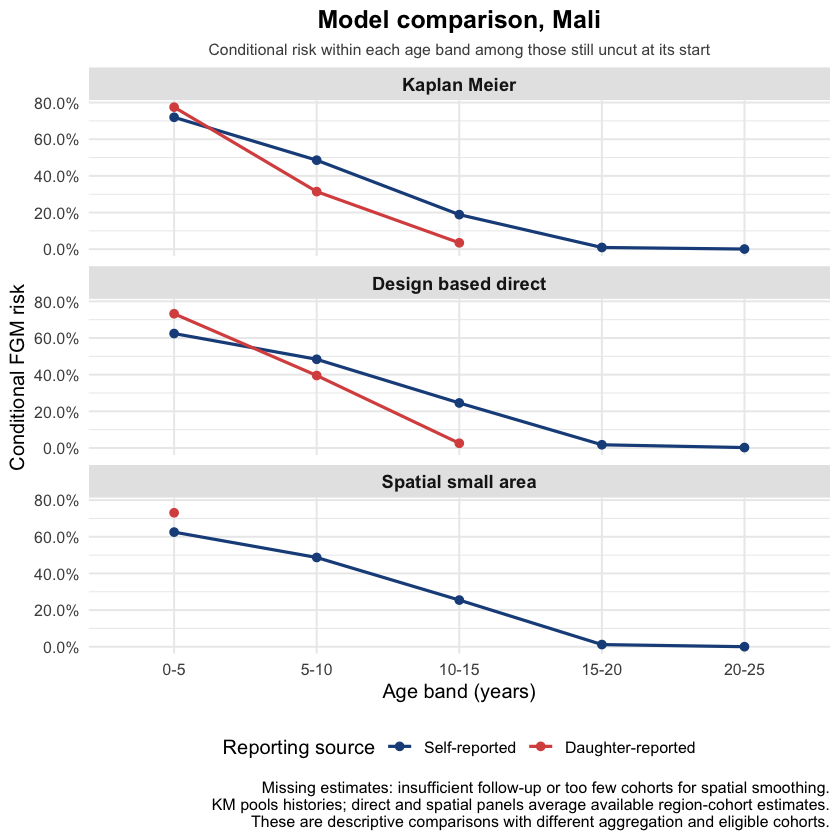

In [73]:
surv_at_t_simple <- function(km_fit, t, max_observed) {
  # Never carry survival forward beyond observed follow-up.
  if (!is.finite(max_observed) || t > max_observed) return(NA_real_)
  if (t <= 0) return(1)
  before <- which(km_fit$time <= t)
  if (length(before) == 0) return(1)
  km_fit$surv[max(before)]
}

national_km_age_band_risk <- function(record_data, record_label) {
  design <- survey::svydesign(ids = ~cluster, strata = ~interaction(survey_year, region), weights = ~weight, data = record_data, nest = TRUE)
  # Keep the weighted Kaplan-Meier point estimator here.
  # svykm(se = TRUE), used for direct estimates, instead uses Aalen survival.
  fit_r <- survey::svykm(survival::Surv(time, fgm_event) ~ 1, design = design)
  max_observed <- max(record_data$time, na.rm = TRUE)
  s <- sapply(age_band_cutpoints, function(t) surv_at_t_simple(fit_r, t, max_observed))
  purrr::map_dfr(seq_along(age_band_cutpoints)[-length(age_band_cutpoints)], function(i) {
    supported <- is.finite(s[i]) && is.finite(s[i + 1]) && s[i] > 0
    tibble::tibble(
      age_band = age_band_levels[i],
      fgm_risk = if (supported) 1 - (s[i + 1] / s[i]) else NA_real_,
      max_observed_age = max_observed,
      estimate_status = if (supported) "Estimated" else "Insufficient follow-up or empty risk set"
    )
  }) |> dplyr::mutate(record_type = record_label, model = "Kaplan Meier")
}

km_national <- dplyr::bind_rows(
  national_km_age_band_risk(fgm_events |> dplyr::filter(record_type == "self"), "self"),
  national_km_age_band_risk(fgm_events |> dplyr::filter(record_type == "daughter"), "daughter")
)

# NOTE: these used to reference age_band_self/age_band_daughter, which are
# never created anywhere in this notebook -- full_risk_self/full_risk_daughter
# (built in the direct-estimates cell) are the correct, actually-existing objects.
direct_national <- dplyr::bind_rows(full_risk_self, full_risk_daughter) |>
  dplyr::group_by(age_band, record_type) |>
  dplyr::summarise(fgm_risk = weighted.mean(event, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(model = "Design based direct")

spatial_national <- dplyr::bind_rows(smoothed_by_band_self, smoothed_by_band_daughter) |>
  dplyr::group_by(age_band, record_type) |>
  dplyr::summarise(fgm_risk = weighted.mean(smoothed_risk, w = sum_weight, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(model = "Spatial small area")

validation_comparison <- dplyr::bind_rows(km_national, direct_national, spatial_national) |>
  dplyr::mutate(
    age_band = factor(age_band, levels = age_band_levels),
    model = factor(model, levels = c("Kaplan Meier", "Design based direct", "Spatial small area")),
    record_type = factor(record_type, levels = c("self", "daughter"), labels = c("Self-reported", "Daughter-reported"))
  )

validation_plot <- ggplot2::ggplot(validation_comparison, ggplot2::aes(
    x = age_band, y = fgm_risk, color = record_type, group = record_type)) +
  ggplot2::geom_line(linewidth = 0.9, na.rm = TRUE) +
  ggplot2::geom_point(size = 2, na.rm = TRUE) +
  ggplot2::facet_wrap(~model, scales = "fixed", ncol = 1) +
  ggplot2::scale_color_manual(values = c("Self-reported" = "#1D4E89", "Daughter-reported" = "#D9534F")) +
  ggplot2::scale_y_continuous(labels = scales::percent_format(accuracy = 0.1)) +
  ggplot2::labs(
    title = paste("Model comparison,", country_name),
    subtitle = "Conditional risk within each age band among those still uncut at its start",
    caption = paste(
      "Missing estimates: insufficient follow-up or too few cohorts for spatial smoothing.",
      "KM pools histories; direct and spatial panels average available region-cohort estimates.",
      "These are descriptive comparisons with different aggregation and eligible cohorts.",
      sep = "\n"
    ),
    y = "Conditional FGM risk", x = "Age band (years)", color = "Reporting source"
  ) +
  ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(
    plot.title = ggplot2::element_text(face = "bold", size = 15, hjust = 0.5),
    plot.subtitle = ggplot2::element_text(size = 9.5, hjust = 0.5, color = "grey30"),
    strip.text = ggplot2::element_text(face = "bold", size = 11),
    strip.background = ggplot2::element_rect(fill = "grey90", color = NA),
    legend.position = "bottom"
  )

print(validation_plot)

ggplot2::ggsave(file.path(output_dir, paste0(country_iso3, "_model_validation.png")),
                 plot = validation_plot, width = 9, height = 11, dpi = 300, bg = "white")

readr::write_csv(validation_comparison, file.path(output_dir, paste0(country_iso3, "_model_validation.csv")))


## 16. Optional machine learning cross check

A random survival forest as a covariate screening and cross check layer, not a replacement for the core survival or small area model, following section 2.5 of the improved methodology document.

In [74]:
if (run_ml_crosscheck) {
  library(randomForestSRC)

  # randomForestSRC::rfsrc() refuses character predictors outright ("please convert all
  # characters to factors"), a pre-existing gap in the original code surfaced now that
  # this cell actually runs, urban_rural/region/survey_type/ethnicity/record_type/
  # birth_cohort come out of 00_EDA_DHS_Country_Year.ipynb as character (birth_cohort is
  # already a factor).
  rsf_data <- fgm_events |>
    dplyr::select(time, fgm_event, urban_rural, region, survey_type, ethnicity, record_type, birth_cohort) |>
    tidyr::drop_na() |>
    dplyr::mutate(dplyr::across(dplyr::where(is.character), as.factor))

  rsf_survey_type_term <- if (dplyr::n_distinct(rsf_data$survey_type) > 1) " + survey_type" else ""
  rsf_record_type_term  <- if (dplyr::n_distinct(rsf_data$record_type) > 1) " + record_type" else ""

  rsf_model <- randomForestSRC::rfsrc(
    as.formula(paste0("Surv(time, fgm_event) ~ urban_rural + region + ethnicity + birth_cohort",
                       rsf_survey_type_term, rsf_record_type_term)),
    data = rsf_data, ntree = 500, importance = TRUE
  )

  print(rsf_model)
  randomForestSRC::vimp(rsf_model)$importance
} else {
  message("Machine learning cross check disabled for this run")
}

                         Sample size: 34507
                    Number of deaths: 24284
                     Number of trees: 500
           Forest terminal node size: 15
       Average no. of terminal nodes: 610.636
No. of variables tried at each split: 3
              Total no. of variables: 5
       Resampling used to grow trees: swor
    Resample size used to grow trees: 21808
                            Analysis: RSF
                              Family: surv
                      Splitting rule: logrank *random*
       Number of random split points: 10
                          (OOB) CRPS: 2.18137282
             (OOB) standardized CRPS: 0.1038749
   (OOB) Requested performance error: 0.33695106



urban_rural       region    ethnicity birth_cohort  record_type 
 0.024636810  0.089568597  0.065389952  0.020511753  0.007215183

## 17. Final outputs

Collect every table and figure produced above into one output folder for this country, ready to feed into a cross country 18 country summary report.

In [75]:
cat("All outputs for", country_name, "written to:", output_dir, "\n")
list.files(output_dir, recursive = TRUE)

All outputs for Mali written to: ../03_Outputs/MLI 


[1] "Attitude_v3/MLI_attitude_association_matrix_v3.csv"                            
 [2] "Attitude_v3/MLI_attitude_association_matrix_v3.png"                            
 [3] "Attitude_v3/MLI_attitude_covariate_adjusted_by_state_v3.csv"                   
 [4] "Attitude_v3/MLI_attitude_covariate_adjusted_map_v3.png"                        
 [5] "Attitude_v3/MLI_attitude_direct_by_state_v3.csv"                               
 [6] "Attitude_v3/MLI_attitude_direct_national_v3.csv"                               
 [7] "Attitude_v3/MLI_attitude_feature_importance_v3.csv"                            
 [8] "Attitude_v3/MLI_attitude_fixed_effects_v3.csv"                                 
 [9] "Attitude_v3/MLI_attitude_model_fit_v3.csv"                                     
[10] "Attitude_v3/MLI_attitude_national_comparison_v3.csv"                           
[11] "Attitude_v3/MLI_attitude_residual_map_v3.png"                                  
[12] "Attitude_v3/MLI_attitude_residual_spatial_effect_v3.csv"                       
[13] "Attitude_v3/MLI_attitude_selected_predictors_v3.csv"                           
[14] "Attitude_v3/MLI_attitude_selected_predictors_v3.rds"                           
[15] "Attitude_v3/MLI_attitude_validation_comparison_v3.csv"                         
[16] "Attitude_v3/MLI_attitude_validation_metrics_v3.csv"                            
[17] "Attitude_v3/MLI_attitude_validation_v3.png"                                    
[18] "Attitude_v3/MLI_attitude_vif_v3.csv"                                           
[19] "FGM_Kaplan_Meier_daughter.pdf"                                                 
[20] "FGM_Kaplan_Meier_daughter.png"                                                 
[21] "FGM_Kaplan_Meier_self.pdf"                                                     
[22] "FGM_Kaplan_Meier_self.png"                                                     
[23] "FGM_Prevalence/MLI_prevalence_association_matrix.csv"                          
[24] "FGM_Prevalence/MLI_prevalence_association_matrix.png"                          
[25] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_by_cohort_daughter.csv"       
[26] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_by_cohort_self.csv"           
[27] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_daughter.csv"                 
[28] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_map_by_cohort_daughter.png"   
[29] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_map_by_cohort_self.png"       
[30] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_map_daughter.png"             
[31] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_map_self.png"                 
[32] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_national_average.csv"         
[33] "FGM_Prevalence/MLI_prevalence_covariate_adjusted_self.csv"                     
[34] "FGM_Prevalence/MLI_prevalence_direct_daughter.csv"                             
[35] "FGM_Prevalence/MLI_prevalence_direct_self.csv"                                 
[36] "FGM_Prevalence/MLI_prevalence_feature_importance.csv"                          
[37] "FGM_Prevalence/MLI_prevalence_map_daughter.png"                                
[38] "FGM_Prevalence/MLI_prevalence_map_self.png"                                    
[39] "FGM_Prevalence/MLI_prevalence_predictor_association_ranking.csv"               
[40] "FGM_Prevalence/MLI_prevalence_residual_map_daughter.png"                       
[41] "FGM_Prevalence/MLI_prevalence_residual_map_self.png"                           
[42] "FGM_Prevalence/MLI_prevalence_residual_spatial_daughter.csv"                   
[43] "FGM_Prevalence/MLI_prevalence_residual_spatial_self.csv"                       
[44] "FGM_Prevalence/MLI_prevalence_smoothed_daughter.csv"                           
[45] "FGM_Prevalence/MLI_prevalence_smoothed_self.csv"                               
[46] "FGM_Prevalence/MLI_prevalence_trend_by_year.png"                               
[47] "FGM_Prevalence/MLI_prevalence_trend_cov